In [5]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
import time
from coffea import hist, nanoevents, util
from coffea.util import load, save
import coffea.processor as processor
import awkward as ak
import numpy as np
import glob as glob
import re
import itertools
# import vector as vec
from coffea.nanoevents.methods import vector, candidate
from coffea.nanoevents import NanoAODSchema, BaseSchema
from coffea.lumi_tools import LumiMask
# for applying JECs
from coffea.lookup_tools import extractor
from coffea.jetmet_tools import FactorizedJetCorrector
from coffea.jetmet_tools import JECStack, CorrectedJetsFactory, JetCorrectionUncertainty, CorrectedMETFactory
from coffea.jetmet_tools import JetResolution, JetResolutionScaleFactor
# from jmeCorrections import JetMetCorrections
import json


import coffea.processor as processor
from coffea import hist
from coffea.analysis_tools import PackedSelection, Weights
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
from coffea.nanoevents.methods import nanoaod

NanoAODSchema.warn_missing_crossrefs = False
from optparse import OptionParser
import pickle
np.errstate(invalid='ignore', divide='ignore')


def METXYCorr_Met_MetPhi(events, year):


    #https://lathomas.web.cern.ch/lathomas/METStuff/XYCorrections/XYMETCorrection_withUL17andUL18andUL16.h
    if 'genWeight' in events.fields:
        isData = False
        print("hi I am MC")
    else: isData = True
    dataset=events.metadata['dataset']   
    met = events.MET
    originalMet = met.pt
    originalMet_phi = met.phi

    npv = events.PV.npvs
    mask = np.asarray(npv>100)
    npv = np.asarray(npv)
    npv[mask==True] = 100


    if not isData:
        if (year == '2016') and ("preVFP" in dataset):
            METxcorr = [-(-0.188743*npv +0.136539)]
            METycorr = [-(0.0127927*npv +0.117747)]

        if (year == '2016') and ("postVFP" in dataset):
            METxcorr = [-(-0.153497*npv +0.231751)]
            METycorr = [-(0.00731978*npv +0.243323)]

        elif year == '2017':
            METxcorr = [-(-0.300155*npv +1.90608)]
            METycorr = [-(0.300213*npv +2.02232)]
        elif year == '2018':
            METxcorr = [-(0.183518*npv +0.546754)]
            METycorr = [-(0.192263*npv +0.42121)]

    if isData:

#                 print(runNMax, runNMin)
        if "2018" in year:
            runNMax = max(events.run)
            runNMin = min(events.run)
            if (runNMin >=315252) and (runNMax <=316995):
                era = "A"

            elif (runNMin >=316998) and (runNMax <=319312):
                era = "B"

            elif (runNMin >=319313) and (runNMax <=320393):
                era = "C"

            elif (runNMin >=320394) and (runNMax <=325273):
                era = "D"
            if "A" in era:
                METxcorr = [-(0.263733*npv -1.91115)]
                METycorr = [-(0.0431304*npv -0.112043)]
            elif "B" in era:
                METxcorr = [-(0.400466*npv -3.05914)]
                METycorr = [-(0.146125*npv -0.533233)]
            elif "C" in era:
                METxcorr = [-(0.430911*npv -1.42865)]
                METycorr = [-(0.0620083*npv -1.46021)]
            elif "D" in era:
                METxcorr = [-(0.457327*npv -1.56856)]
                METycorr = [-(0.0684071*npv -0.928372)]


        if "2017" in year:

            runNMax = max(events.run)
            runNMin = min(events.run)
            if (runNMin >=297020) and (runNMax <=299329):
                era = "B"

            elif (runNMin >=299337) and (runNMax <=302029):
                era = "C"

            elif (runNMin >=302030) and (runNMax <=303434):
                era = "D"

            elif (runNMin >=303435) and (runNMax <=304826):
                era = "E"

            elif (runNMin >=304911) and (runNMax <=306462):
                era = "F"

            else: era = "X"
            if "E" in era:
                METxcorr = [-(-0.162472*npv +0.176329)]
                METycorr = [-(0.138076*npv -0.250239)]
            elif "B" in era:
                METxcorr = [-(-0.211161*npv +0.419333)]
                METycorr = [-(0.251789*npv -1.28089)]
            elif "C" in era:
                METxcorr = [-(-0.185184*npv -0.164009)]
                METycorr = [-(0.200941*npv -0.56853)]
            elif "D" in era:
                METxcorr = [-(-0.201606*npv +0.426502)]
                METycorr = [-(0.188208*npv -0.58313)]
            elif "F" in era:
                METxcorr = [-(-0.210639*npv +0.72934)]
                METycorr = [-(0.198626*npv +1.028)]
            elif "X" in era:
                METxcorr = [np.zeros(len(events))]
                METycorr = [np.zeros(len(events))]
        if "2016" in year:
            runNMax = max(events.run)
            runNMin = min(events.run)

            if (runNMin >=272007) and (runNMax <=275376):
                era = "B"
                print(era)
            elif (runNMin >=275656) and (runNMax <=276283):
                era = "C"
                print('runNMax', runNMax, 'runMin', runNMin, ' era:', era)
#                         print(era)
            elif (runNMin >=276315) and (runNMax <=276811):
                era = "D"
                print(era)
            elif (runNMin >=276831) and (runNMax <=277420) :
                era = "E"
                print(era)
            elif (runNMin >=277772 and runNMax <=278807) or (runNMin in [278770, 278806, 278807]) or (runNMax in [278770, 278806, 278807] ):
                era = "F"
#                  https://twiki.cern.ch/twiki/bin/viewauth/CMS/PdmVDatasetsUL2016
                print(era)
            elif (runNMin >=278801 and runNMax <=278808) or (runNMax in [278769, 278806, 278807]) or (runNMax in [278769,278806, 278807]):
                era = "F_late"
                print(era)
            elif (runNMin >=278820) and (runNMax <=280385):
                era = "G"
                print(era)
            elif (runNMin >=281613) and (runNMax <=284044):
                era = "H"
                print(era)

            if "B" in era:
                METxcorr = [-(-0.0214894*npv -0.188255)]
                METycorr = [-(0.0876624*npv +0.812885)]
            elif "C" in era:
                METxcorr = [-(-0.032209*npv +0.067288)]
                METycorr = [-(0.113917*npv +0.743906)]
            elif "D" in era:
                METxcorr = [-(-0.0293663*npv +0.21106)]
                METycorr = [-(0.11331*npv +0.815787)]
            elif "E" in era:
                METxcorr = [-(-0.0132046*npv +0.20073)]
                METycorr = [-(0.134809*npv +0.679068)] 
            elif "F" in era:
                METxcorr = [-(-0.0543566*npv +0.816597)]
                METycorr = [-(0.114225*npv +1.17266)] 
            elif "F_late" in era:
                METxcorr = [-(0.134616*npv -0.89965)]
                METycorr = [-(0.0397736*npv +1.0385)] 
            elif "G" in era:
                METxcorr = [-(0.121809*npv -0.584893)]
                METycorr = [-(0.0558974*npv +0.891234)]
            elif "H" in era:
                METxcorr = [-(0.0868828*npv -0.703489)]
                METycorr = [-(0.0888774*npv +0.902632)]

    CorrectedMET_x = np.multiply(originalMet,np.cos(originalMet_phi))+ (np.array(METxcorr)).flatten()
    CorrectedMET_y = np.multiply(originalMet,np.sin(originalMet_phi))+ (np.array(METycorr)).flatten()
#             print(CorrectedMET_x/CorrectedMET_y)

    CorrectedMET = np.sqrt(np.square(CorrectedMET_x)+np.square(CorrectedMET_y))
    CorrectedMETPhi = np.zeros(len(events))

#             print(CorrectedMET)
#             print(CorrectedMETPhi)

    mask1 = (CorrectedMET_x ==0 )& (CorrectedMET_y > 0)
    CorrectedMETPhi[mask1==True] = np.pi

    mask2 = (CorrectedMET_x ==0 )& (CorrectedMET_y < 0)
    CorrectedMETPhi[mask2==True] = -np.pi

    mask3 = (CorrectedMET_x <0 )& (CorrectedMET_y > 0)
    CorrectedMETPhi[mask3==True] = (np.arctan(CorrectedMET_y/CorrectedMET_x) + np.pi )[mask3==True] 

    mask4 = (CorrectedMET_x <0 )& (CorrectedMET_y < 0)
    CorrectedMETPhi[mask4==True] = (np.arctan(CorrectedMET_y/CorrectedMET_x) - np.pi )[mask4==True]

    mask5 = (CorrectedMET_x >0 )
    CorrectedMETPhi[mask5==True] = (np.arctan(CorrectedMET_y/CorrectedMET_x))[mask5==True]   

    mask6 = (~mask1 & ~mask2 & ~mask3 & ~mask4 & ~mask5) 
    CorrectedMETPhi[mask6==True] = 0

    return (CorrectedMET, CorrectedMETPhi)


class AnalysisProcessor(processor.ProcessorABC):
    
    
    lumis = {  # Values from https://twiki.cern.ch/twiki/bin/viewauth/CMS/PdmVAnalysisSummaryTable
        '2016': {'preVFP':19.52,'postVFP':16.81},
                 #postVFP
        '2017': 40.66,
        '2018': 59.74
    }

    
    met_filter_flags = {

        '2016': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
#                  'BadPFMuonDzFilter',
                 'eeBadScFilter',
                 
                 ],

        '2017': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
                 'ecalBadCalibFilter',
                 'eeBadScFilter',
                 'BadPFMuonDzFilter',
                 'hfNoisyHitsFilter'
                 ],

        '2018': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
                 'ecalBadCalibFilter',
                 'eeBadScFilter',
                 'BadPFMuonDzFilter',
                 'hfNoisyHitsFilter'
                 ]
    }

    def __init__(self, year, xsec, corrections, ids, common, vfp):
        ak.behavior.update(nanoaod.behavior)
        self._year = year
        if self._year == "2016":
            self._lumi = 1000.*float(AnalysisProcessor.lumis[year][vfp])
        else:   
            self._lumi = 1000.*float(AnalysisProcessor.lumis[year])

        self._xsec = xsec
        
        self._samples = {
            'sre':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD', 'SingleElectron','EGamma',
                   'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'srm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon',
                    'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'ttbare':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleElectron','EGamma',
                     'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'ttbarm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon',
                     'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'wjete':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD', 'SingleElectron','EGamma',
                    'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'wjetm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon',
                    'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
        }
        
        self._singleelectron_triggers = {  # 2017 and 2018 from monojet, applying dedicated trigger weights
            '2016': [
                'Ele27_WPTight_Gsf',
#                 'Ele105_CaloIdVT_GsfTrkIdT'
                'Ele115_CaloIdVT_GsfTrkIdT'
                'Ele50_CaloIdVT_GsfTrkIdT_PFJet165'
            ],
            '2017': [
                'Ele35_WPTight_Gsf',
                'Ele115_CaloIdVT_GsfTrkIdT',
                'Photon200'
            ],
            '2018': [
                'Ele32_WPTight_Gsf',
                'Ele115_CaloIdVT_GsfTrkIdT',
                'Photon200','Ele50_CaloIdVT_GsfTrkIdT_PFJet165'
            ]
        }
        
        self._singlemuon_triggers = {
            '2016': [
                'IsoMu24',
                'IsoTkMu24',
                'Mu50',
                'TkMu50'

            ],
            '2017':
                [
                'IsoMu27',
                'Mu50',
                'OldMu100',
                'TkMu100'
            ],
            '2018':
                [
                'IsoMu24',
                'Mu50',
                'OldMu100',
                'TkMu100'
            ]
        }
        

        self._jec = {

            '2016':  
                    {
                        'no_apv':
                        ['Summer19UL16_V7_MC_L1FastJet_AK4PFchs',
                        'Summer19UL16_V7_MC_L2L3Residual_AK4PFchs',
                        'Summer19UL16_V7_MC_L2Relative_AK4PFchs',
                        'Summer19UL16_V7_MC_L2Residual_AK4PFchs',
                        'Summer19UL16_V7_MC_L3Absolute_AK4PFchs'],
                    
                        'apv':
                        ['Summer19UL16APV_V7_MC_L1FastJet_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L2L3Residual_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L2Relative_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L2Residual_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L3Absolute_AK4PFchs']
                    },


            '2017': [
                'Summer19UL17_V5_MC_L1FastJet_AK4PFchs',
                'Summer19UL17_V5_MC_L2L3Residual_AK4PFchs',
                'Summer19UL17_V5_MC_L2Relative_AK4PFchs',
                'Summer19UL17_V5_MC_L2Residual_AK4PFchs',
                'Summer19UL17_V5_MC_L3Absolute_AK4PFchs'
                
            ],

            '2018': [
                'Summer19UL18_V5_MC_L1FastJet_AK4PFchs',
                'Summer19UL18_V5_MC_L2L3Residual_AK4PFchs',
                'Summer19UL18_V5_MC_L3Absolute_AK4PFchs',
                'Summer19UL18_V5_MC_L2Relative_AK4PFchs',
                'Summer19UL18_V5_MC_L2Residual_AK4PFchs',
                'Summer19UL18_V5_MC_L3Absolute_AK4PFchs'
                     
            ]
        }
        
        self._junc = {

            '2016': 
            {
            'no_apv': ['Summer19UL16_V7_MC_Uncertainty_AK4PFchs'],
                     'apv': ['Summer19UL16APV_V7_MC_Uncertainty_AK4PFchs']},
#                 'Summer16_07Aug2017_V11_MC_Uncertainty_AK4PFchs',
            

            '2017': [
                'Summer19UL17_V5_MC_Uncertainty_AK4PFchs'
#                 'Fall17_17Nov2017_V32_MC_Uncertainty_AK4PFchs'
            ],

            '2018': [
                'Summer19UL18_V5_MC_Uncertainty_AK4PFchs'
#                 'Autumn18_V19_MC_Uncertainty_AK4PFchs'
            ],
        }
        
        self._jr = {

            '2016': 
            {'apv': ['Summer20UL16APV_JRV3_MC_PtResolution_AK4PFchs'],
                     'no_apv': ['Summer20UL16_JRV3_MC_PtResolution_AK4PFchs']},
#                 'Summer16_25nsV1b_MC_PtResolution_AK4PFchs',


            '2017': [
                'Summer19UL17_JRV2_MC_PtResolution_AK4PFchs'
#                 'Fall17_V3b_MC_PtResolution_AK4PFchs'
            ],

            '2018': [
                'Summer19UL18_JRV2_MC_PtResolution_AK4PFchs'
#                 'Autumn18_V7b_MC_PtResolution_AK4PFchs'
            ]
        }
        
        self._jersf = {

            '2016': 
            {'no_apv':['Summer20UL16_JRV3_MC_SF_AK4PFchs'],
                     'apv':['Summer20UL16APV_JRV3_MC_SF_AK4PFchs']},
#                 'Summer16_25nsV1b_MC_SF_AK4PFchs',
            

            '2017': [
                'Summer19UL17_JRV2_MC_SF_AK4PFchs'
#                 'Fall17_V3b_MC_SF_AK4PFchs'
            ],

            '2018': [
                'Summer19UL18_JRV2_MC_SF_AK4PFchs'
#                 'Autumn18_V7b_MC_SF_AK4PFchs'
            ]
        }
        
        self._golden_json_path = {
    '2016': '../../data/golden_txt/Cert_271036-284044_13TeV_Legacy2016_Collisions16_JSON.txt',
    '2017': '../../data/golden_txt/Cert_294927-306462_13TeV_UL2017_Collisions17_GoldenJSON.txt',
    '2018': '../../data/golden_txt/Cert_314472-325175_13TeV_Legacy2018_Collisions18_JSON.txt',
}
        self._corrections = corrections
        self._ids = ids
        self._common = common

        self._accumulator = processor.dict_accumulator({
            'sumw': hist.Hist(
                'sumw',
                hist.Cat('dataset', 'Dataset'),
                hist.Bin('sumw', 'Weight value', [0.])),
            
            'template': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mT_corrected', '$m_{T}$ [GeV] Corrected', 20, 0, 600)),
            
            'mT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mT', '$m_{T}$ [GeV]', 20, 0, 600)),
            'mT_corrected': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mT_corrected', '$m_{T} XY \Phi Corrected$ [GeV]', 20, 0, 600)),
#             "EventCount": processor.value_accumulator(int),
            'cutflow': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
#                 hist.Bin('cut', 'Cut index', 11, 0, 11),
                hist.Bin('cut', 'Cut index', [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17])),
            'eT_miss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('eT_miss', '$E^T_{miss}$[GeV]', 20, 0, 600)),
            'eT_miss_corrected': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('eT_miss_corrected', '$E^T_{miss} Corrected$[GeV]', 20, 0, 600)),
            'ele_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_pT', 'Tight electron $p_{T}$ [GeV]', 10, 0, 200)),
            'leading_mu_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('leading_mu_pT', 'Leading Muon $p_{T}$ [GeV]', 10, 0, 200)),
            'mu_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mu_pT', 'Tight Muon $p_{T}$ [GeV]', 10, 0, 200)),
            'W_gen_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('W_gen_pT', 'W Boson Gen $p_{T}$ [GeV]', 50, 0, 1000)), 
            'Z_gen_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('Z_gen_pT', 'Z Boson Gen $p_{T}$ [GeV]', 50, 0, 1000)),
            'j1pt': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('j1pt','AK4 Leading Jet Pt',[30.0, 60.0, 90.0, 120.0, 150.0, 180.0, 210.0, 250.0, 280.0, 310.0, 340.0, 370.0, 400.0, 430.0, 470.0, 510.0, 550.0, 590.0, 640.0, 690.0, 740.0, 790.0, 840.0, 900.0, 960.0, 1020.0, 1090.0, 1160.0, 1250.0])
            ),
            'j1eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('j1eta','AK4 Leading Jet Eta',35,-3.5,3.5)),
            
            'j1phi': hist.Hist(
                'Events', 
                hist.Cat('dataset', 'Dataset'), 
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('j1phi','AK4 Leading Jet Phi',35,-3.5,3.5)),

            'dphi_e_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dphi_e_etmiss', '$\Delta\phi (e, E^T_{miss} )$', 30, 0, 3.5)),
            
            'dphi_mu_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dphi_mu_etmiss','$\Delta\phi (\mu, E^T_{miss} )$', 30, 0, 3.5)),
            
            'ndflvL': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ndflvL', 'AK4 Number of deepFlavor Loose Jets', 6, -0.5, 5.5)),
            'ndflvM': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ndflvM', 'AK4 Number of deepFlavor Medium Jets', 6, -0.5, 5.5)),
            'njets': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('njets', 'AK4 Number of Jets', 7, -0.5, 6.5)),

            'ndcsvM': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ndcsvM', 'AK4 Number of deepCSV Medium Jets', 6, -0.5, 5.5)),
            
            'dphi_Met_LJ': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dphi_Met_LJ', '$\Delta \Phi (E^T_{miss}, Leading Jet)$', 30, 0, 3.5)),
            'dphi_Corr_Met_LJ': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dphi_Corr_Met_LJ', '$\Delta \Phi (E^T_{miss corr}, Leading Jet)$', 30, 0, 3.5)),
            'dr_e_lj': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dr_e_lj', '$\Delta r (Leading e, Leading Jet)$', 30, 0, 5.0)),
            'dr_mu_lj': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dr_mu_lj', '$\Delta r (Leading \mu, Leading Jet)$', 30, 0, 5.0)),
            'ele_eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_eta', 'Leading Electron Eta', 48, -2.4, 2.4)),
            'mu_eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mu_eta', 'Leading Muon Eta', 48, -2.4, 2.4)),
            'ele_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_phi', 'Leading Electron Phi', 64, -3.2, 3.2)),
            
            'ele_phi_loose': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_phi_loose', 'Loose Electron Phi', 64, -3.2, 3.2)),
            'metphi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('metphi','MET phi',35,-3.5,3.5)),
            'eT_miss_corrected_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('eT_miss_corrected_phi','MET phi Corrected',35,-3.5,3.5)),
            'mu_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mu_phi', 'Leading Muon Phi', 64, -3.2, 3.2)),
 
        })

    @property
    def accumulator(self):
        return self._accumulator



    def process(self, events):
        ## Here we pre-compute a few common variables that we will re-use later and add them to the events object

        # Temporary patch so we can add photon and lepton four vectors. Not needed for newer versions of NanoAOD
        events["Photon", "charge"] = 0
        # Calculate charged hadron isolation for photons
        events["Photon", "chIso"] = (events.Photon.pfRelIso03_chg) * (events.Photon.pt)
        self.isMC ='genWeight' in events.fields
        # Calculate the maximum pdgID of any of the particles in the GenPart history
#         if self.isMC:
#             idx = ak.to_numpy(ak.flatten(abs(events.GenPart.pdgId)))
#             par = ak.to_numpy(ak.flatten(events.GenPart.genPartIdxMother))
#             num = ak.to_numpy(ak.num(events.GenPart.pdgId))
#             maxParentFlatten = maxHistoryPDGID(idx, par, num)
#             events["GenPart", "maxParent"] = ak.unflatten(maxParentFlatten, num)

        if self.isMC:
            output = self.accumulator.identity()
            shift_systs = [None,]
#             shift_systs = [None, "JESUp", "JESDown", "JERUp", "JERDown", "METunclUp", "METunclDown"]
            for _syst in shift_systs:
                output += self.process_shift(events, _syst)
        else:
            # data doesn't need each systematic shift to be processed
            output = self.process_shift(events, "nominal")

        # only add events up once
#         output["EventCount"] += len(events)
        return output
            
    def process_shift(self, events, shift_syst=None):
            
        dataset = events.metadata['dataset']
        isData = 'genWeight' not in events.fields
        isMC = 'genWeight' in events.fields
        selection = processor.PackedSelection()
        hout = self.accumulator.identity()
            
        selected_regions = []
        for region, samples in self._samples.items():
            for sample in samples:
                if sample not in dataset:
                    continue
                selected_regions.append(region)
            
        ###
        # Getting corrections, ids from .coffea files
        ###
        if ("preVFP" in dataset) and (self._year == '2016'):
            get_ele_loose_id_sf = self._corrections['get_ele_tight_id_sf_preVFP'][self._year]
            get_ele_tight_id_sf = self._corrections['get_ele_tight_id_sf_preVFP'][self._year]
            
            get_ele_reco_sf = self._corrections['get_ele_reco_sf_preVFP_above20'][self._year]
            get_ele_reco_err = self._corrections['get_ele_reco_err_preVFP_above20'][self._year]
            
            get_ele_reco_lowet_sf = self._corrections['get_ele_reco_sf_preVFP_below20'][self._year]
            get_ele_reco_lowet_err = self._corrections['get_ele_reco_err_preVFP_below20'][self._year]
            
            get_mu_tight_id_sf = self._corrections['get_mu_tight_id_sf_preVFP'][self._year]
            get_mu_loose_id_sf = self._corrections['get_mu_loose_id_sf_preVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_preVFP'][self._year]
            get_mu_loose_err_sf = self._corrections['get_mu_loose_id_err_preVFP'][self._year]            
            
            
            get_mu_tight_iso_sf = self._corrections['get_mu_tight_iso_sf_preVFP'][self._year]
            get_mu_loose_iso_sf = self._corrections['get_mu_loose_iso_sf_preVFP'][self._year]
            get_mu_tight_iso_err = self._corrections['get_mu_tight_iso_err_preVFP'][self._year]
            get_mu_loose_iso_err = self._corrections['get_mu_loose_iso_err_preVFP'][self._year]            

            
            get_mu_trig_weight = self._corrections['get_mu_trig_weight_preVFP'][self._year]
            get_mu_trig_err = self._corrections['get_mu_trig_weight_preVFP'][self._year]
            get_ele_loose_id_err = self._corrections['get_ele_loose_id_err_preVFP'][self._year]
            get_ele_tight_id_err = self._corrections['get_ele_tight_id_err_preVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_preVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_preVFP'][self._year]
            
            get_deepflav_weight = self._corrections['get_btag_weight_preVFP']['deepflav'][self._year]
            
        elif ("postVFP" in dataset) and (self._year == '2016'):
            get_ele_loose_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            get_ele_tight_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            
            get_ele_reco_sf = self._corrections['get_ele_reco_sf_postVFP_above20'][self._year]
            get_ele_reco_err = self._corrections['get_ele_reco_err_postVFP_above20'][self._year]
            
            get_ele_reco_lowet_sf = self._corrections['get_ele_reco_sf_postVFP_below20'][self._year]
            get_ele_reco_lowet_err = self._corrections['get_ele_reco_err_postVFP_below20'][self._year]
            
            
            get_mu_tight_id_sf = self._corrections['get_mu_tight_id_sf_postVFP'][self._year]
            get_mu_loose_id_sf = self._corrections['get_mu_loose_id_sf_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]            
            
            get_mu_tight_iso_sf = self._corrections['get_mu_tight_iso_sf_postVFP'][self._year]
            get_mu_loose_iso_sf = self._corrections['get_mu_loose_iso_sf_postVFP'][self._year]
            get_mu_tight_iso_err = self._corrections['get_mu_tight_iso_err_postVFP'][self._year]
            get_mu_loose_iso_err = self._corrections['get_mu_loose_iso_err_postVFP'][self._year]
            
            
            get_mu_trig_weight = self._corrections['get_mu_trig_weight_postVFP'][self._year]
            get_mu_trig_err = self._corrections['get_mu_trig_weight_postVFP'][self._year]
            get_ele_loose_id_err = self._corrections['get_ele_loose_id_err_postVFP'][self._year]
            get_ele_tight_id_err = self._corrections['get_ele_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            
            get_deepflav_weight = self._corrections['get_btag_weight_postVFP']['deepflav'][self._year]

        else:
#             print("hi")
            get_ele_loose_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            get_ele_tight_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            
            get_ele_reco_sf = self._corrections['get_ele_reco_sf_postVFP_above20'][self._year]
            get_ele_reco_err = self._corrections['get_ele_reco_err_postVFP_above20'][self._year]
            
            get_ele_reco_lowet_sf = self._corrections['get_ele_reco_sf_postVFP_below20'][self._year]
            get_ele_reco_lowet_err = self._corrections['get_ele_reco_err_postVFP_below20'][self._year]
            
            
            get_mu_tight_id_sf = self._corrections['get_mu_tight_id_sf_postVFP'][self._year]
            get_mu_loose_id_sf = self._corrections['get_mu_loose_id_sf_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]            
            
            get_mu_tight_iso_sf = self._corrections['get_mu_tight_iso_sf_postVFP'][self._year]
            get_mu_loose_iso_sf = self._corrections['get_mu_loose_iso_sf_postVFP'][self._year]
            get_mu_tight_iso_err = self._corrections['get_mu_tight_iso_err_postVFP'][self._year]
            get_mu_loose_iso_err = self._corrections['get_mu_loose_iso_err_postVFP'][self._year]
            
            
            get_mu_trig_weight = self._corrections['get_mu_trig_weight_postVFP'][self._year]
            get_mu_trig_err = self._corrections['get_mu_trig_weight_postVFP'][self._year]
            get_ele_loose_id_err = self._corrections['get_ele_loose_id_err_postVFP'][self._year]
            get_ele_tight_id_err = self._corrections['get_ele_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            
            get_deepflav_weight = self._corrections['get_btag_weight_postVFP']['deepflav'][self._year]

        get_ttbar_weight = self._corrections['get_ttbar_weight']
        get_nnlo_nlo_weight = self._corrections['get_nnlo_nlo_weight'][self._year]
        get_nlo_qcd_weight = self._corrections['get_nlo_qcd_weight'][self._year]
        get_nlo_ewk_weight = self._corrections['get_nlo_ewk_weight'][self._year]
        get_pu_weight = self._corrections['get_pu_weight'][self._year]

        get_ele_trig_weight = self._corrections['get_ele_trig_weight'][self._year]
        get_ele_trig_err    = self._corrections['get_ele_trig_err'][self._year]
        get_pho_tight_id_sf = self._corrections['get_pho_tight_id_sf'][self._year]
        get_pho_csev_sf = self._corrections['get_pho_csev_sf'][self._year]
        get_ecal_bad_calib = self._corrections['get_ecal_bad_calib']

        Jetevaluator = self._corrections['Jetevaluator']
            
        isLooseElectron = self._ids['isLooseElectron']
        isTightElectron = self._ids['isTightElectron']
        isLooseMuon = self._ids['isLooseMuon']
        isTightMuon = self._ids['isTightMuon']
        isLooseTau = self._ids['isLooseTau']
        isLoosePhoton = self._ids['isLoosePhoton']
        isTightPhoton = self._ids['isTightPhoton']
        isGoodJet = self._ids['isGoodJet']
        isHEMJet = self._ids['isHEMJet']

        match = self._common['match']
        # to calculate photon trigger efficiency
        sigmoid = self._common['sigmoid']
        deepflavWPs = self._common['btagWPs']['deepflav'][self._year]
        deepcsvWPs = self._common['btagWPs']['deepcsv'][self._year]
            
        ###
        # Derive jet corrector for JEC/JER
        ### Not taking JEC because they have already been applied
        jec_names = []
#         print(type(self._jr[self._year]['apv']))
#         print(type(self._jr[self._year]['no_apv']))
        
#         print(type(self._junc[self._year]['apv']))
#         print(type(self._junc[self._year]['no_apv']))
        
#         print(type(self._jersf[self._year]['apv']))
#         print(type(self._jersf[self._year]['no_apv']))        
#         import sys
#         sys.exit(0)
#         list_of_jr = []
        if (self._year == '2016'):
            if ("preVFP" in dataset):
#                 print(self._jr[self._year]['apv'][0])
#                 list_of_jec = self._jec[self._year]['apv']
                list_of_jr = self._jr[self._year]['apv']
                list_of_junc = self._junc[self._year]['apv']
                list_of_jersf = self._jersf[self._year]['apv']
            else: 
#                 list_of_jec = self._jec[self._year]['apv']
                list_of_jr =self ._jr[self._year]['no_apv']
                list_of_junc =self ._junc[self._year]['no_apv']
                list_of_jersf = self._jersf[self._year]['no_apv']
                
#             for name in list_of_jec:
#                 jec_names.append(name)
            for name in list_of_jr:
                jec_names.append(name)
            for name in list_of_junc:
                jec_names.append(name)    
            for name in list_of_jersf:
                jec_names.append(name)                
        else:
#             for name in self._jec[self._year]:
#                 jec_names.append(name)                 
            for name in self._jr[self._year]:
                jec_names.append(name)    
            for name in self._jersf[self._year]:
                jec_names.append(name)
            for name in self._junc[self._year]:
                jec_names.append(name)
            
        j = events.Jet
        met = events.MET
        if isMC:
            jec_inputs = {name: Jetevaluator[name] for name in jec_names}
            jec_stack = JECStack(jec_inputs)

            jec_name_map = jec_stack.blank_name_map
            jec_name_map = {
                'JetPt': 'pt',
                'JetMass': 'mass',
                'JetEta': 'eta',
                'JetA': 'area',
                'ptGenJet': 'pt_gen',
                'ptRaw': 'pt_raw',
                'massRaw': 'mass_raw',
                'Rho': 'rho',
                'METpt': 'pt',
                'METphi': 'phi',
                'JetPhi': 'phi',
                'UnClusteredEnergyDeltaX': 'MetUnclustEnUpDeltaX',
                'UnClusteredEnergyDeltaY': 'MetUnclustEnUpDeltaY',
            }
            
            jet_factory = CorrectedJetsFactory(jec_name_map, jec_stack)

            events["Jet", "pt_raw"] = (1 - events.Jet.rawFactor) * events.Jet.pt
            events["Jet", "mass_raw"] = (1 - events.Jet.rawFactor) * events.Jet.mass
            events["Jet", "pt_gen"] = ak.values_astype(
                ak.fill_none(events.Jet.matched_gen.pt, 0), np.float32
            )
            events["Jet", "rho"] = ak.broadcast_arrays( events.fixedGridRhoFastjetAll, events.Jet.pt)[0]


            events_cache = events.caches[0]
            met_factory = CorrectedMETFactory(jec_name_map)
            corrected_jets = jet_factory.build(events.Jet, lazy_cache=events_cache)
            met = met_factory.build(events.MET, events.Jet, {})
            
            
            if shift_syst == "JESUp":
                j = corrected_jets['JES_jes'].up
#                 print(shift_syst)

            elif shift_syst == "JESDown":
                j = corrected_jets['JES_jes'].down
#                 print(shift_syst)

            elif shift_syst == "JERUp":
                j = corrected_jets['JER'].up
#                 print(shift_syst)

            elif shift_syst == "JERDown":
                j = corrected_jets['JER'].down
#                 print(shift_syst)

            elif shift_syst == "METunclUp":
                met = met.MET_UnclusteredEnergy.up
                j   = events.Jet
            
            elif shift_syst == "METunclDown":
                met = met.MET_UnclusteredEnergy.down
                j   = events.Jet
                
            else:
                j   = corrected_jets
                met = events.MET
#                 print(shift_syst)
        ###
        # Initialize global quantities (MET ecc.)
        ###
        
        
        met["T"] = ak.zip({"pt": met.pt, "phi": met.phi}, 
                          with_name="PolarTwoVector", 
                          behavior=vector.behavior)

        calomet = events.CaloMET
        puppimet = events.PuppiMET
        puppimet["T"] = ak.zip({"pt": puppimet.pt, "phi": puppimet.phi}, 
                          with_name="PolarTwoVector", 
                          behavior=vector.behavior)
        
        
###################################################################################
    # Met Phi X-Y corrections
    

        XY_correctedmet_pt , XY_correctedmet_phi = METXYCorr_Met_MetPhi(events, self._year)

        corrected_met = events.MET
        corrected_met["T"] = ak.zip({"pt": XY_correctedmet_pt, "phi": XY_correctedmet_phi}, 
                          with_name="PolarTwoVector", 
                          behavior=vector.behavior)
##################################################################################
        ###
        # Initialize physics objects
        ###


            
        mu = events.Muon
        mu['isloose'] = isLooseMuon(mu.pt, mu.eta, mu.pfRelIso04_all, mu.looseId, self._year)
        mu['istight'] = isTightMuon(mu.pt, mu.eta, mu.pfRelIso04_all, mu.tightId, self._year)
        mu["T"] = ak.zip({"pt": mu.pt, "phi": mu.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)
        mu['p4'] = ak.zip({
                            "pt": mu.pt,
                            "eta": mu.eta,
                            "phi": mu.phi,
                            "mass": mu.mass},
                            with_name="PtEtaPhiMLorentzVector",
        )
    

        mu_loose = mu[ak.values_astype(mu.isloose, np.bool)]
        mu_tight = mu[ak.values_astype(mu.istight, np.bool)]
        mu_ntot = ak.num(mu, axis=1)
        mu_nloose = ak.num(mu_loose, axis=1)
        mu_ntight = ak.num(mu_tight, axis=1)
        leading_mu = mu[:,:1]
        leading_mu = leading_mu[ak.values_astype(leading_mu.istight, np.bool)]
        
        
        e = events.Electron
        event_size = len(events)
        e['isclean'] = ~(ak.any(e.metric_table(mu_loose) < 0.3, axis=-1))
        e['isloose'] = isLooseElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, self._year)
        e['istight'] = isTightElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, self._year)
#         e['T'] = TVector2Array.from_polar(e.pt, e.phi)
        e["T"] = ak.zip({"pt": e.pt, "phi": e.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)
        e['p4'] = ak.zip({
                            "pt": e.pt,
                            "eta": e.eta,
                            "phi": e.phi,
                            "mass": e.mass},
                            with_name="PtEtaPhiMLorentzVector",
        )
        e_clean = e[ak.values_astype(e.isclean, np.bool)]
        e_loose = e_clean[ak.values_astype(e_clean.isloose, np.bool)]
        e_tight = e_clean[ak.values_astype(e_clean.istight, np.bool)]
        e_ntot = ak.num(e, axis=1)
        e_nloose = ak.num(e_loose, axis=1)

#         e_nloose = e_loose.counts
        e_ntight = ak.num(e_tight, axis=1)
        leading_e = e[:,:1]
        leading_e = leading_e[ak.values_astype(leading_e.isclean, np.bool)]
        leading_e = leading_e[ak.values_astype(leading_e.istight, np.bool)]
        

        tau = events.Tau
        tau['isclean'] = ~(ak.any(tau.metric_table(mu_loose) < 0.4, axis=-1)) & ~(ak.any(tau.metric_table(e_loose) < 0.4, axis=-1))
#         ak.all(tau.metric_table(mu_loose) > 0.4, axis=-1)
        try:
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayMode,tau.idDeepTau2017v2p1VSjet,self._year)
        except:
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeOldDMs,tau.idDeepTau2017v2p1VSjet,self._year)
        else: 
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeNewDMs,tau.idDeepTau2017v2p1VSjet,self._year)

        tau_clean = tau[ak.values_astype(tau.isclean, np.bool)]

        tau_loose = tau_clean[ak.values_astype(tau_clean.isloose, np.bool)]
        tau_ntot = ak.num(tau, axis=1)
        tau_nloose = ak.num(tau_loose, axis=1)

        pho = events.Photon
        pho['isclean'] = ~(ak.any(pho.metric_table(mu_loose) < 0.4, axis=-1)) & ~(ak.any(pho.metric_table(e_loose) < 0.4, axis=-1))
        _id = 'cutBased'
        if self._year == '2016':
            _id = 'cutBased'
        pho['isloose'] = isLoosePhoton(pho.pt, pho.eta, pho[_id], self._year) & (pho.electronVeto)  # added electron veto flag
        pho['istight'] = isTightPhoton(pho.pt, pho[_id], self._year) & (pho.isScEtaEB) & (pho.electronVeto)  # tight photons are barrel only

        pho["T"] = ak.zip({"pt": pho.pt, "phi": pho.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)
    
        pho_clean = pho[ak.values_astype(pho.isclean, np.bool)]
        pho_loose = pho_clean[ak.values_astype(pho_clean.isloose, np.bool)]
        pho_tight = pho_clean[ak.values_astype(pho_clean.istight, np.bool)]
        pho_ntot = ak.num(pho,axis=1)
        pho_nloose = ak.num(pho_loose, axis=1)
        pho_ntight = ak.num(pho_tight, axis=1)
        leading_pho = pho[:,:1] #new way to define leading photon
        leading_pho = leading_pho[ak.values_astype(leading_pho.isclean, np.bool)]
        leading_pho = leading_pho[ak.values_astype(leading_pho.istight, np.bool)]

#         j = events.Jet
#         JET Corrections
#         JEC Already applied in nanoAOD
#         Junc Already applied in nanoAOD
#         Jer  to be applied
#         JERSF  to be applied
        def jetcleaning(j, mu_loose, e_loose, pho_loose, r):
            NumNeutralParticles = (j.nConstituents-j.nElectrons+j.nMuons)
            NumConst = j.nConstituents
            NHF = j.neHEF
            NEMF = j.neEmEF
            CHF = j.chHEF
            MUF = j.muEF
            CEMF = j.chEmEF
            CHM = j.nElectrons+j.nMuons

            jetMuMask = ak.any(j.metric_table(mu_loose) < r, axis=-1)
            jetEleMask = ak.any(j.metric_table(e_loose) < r, axis=-1)
            jetPhoMask = ak.any(j.metric_table(pho_loose) < r, axis=-1)

            j_isclean_mask = (~jetMuMask & ~jetEleMask & ~jetPhoMask)
            j_isgood_mask = isGoodJet(j.pt, j.eta, j.jetId, j.puId,NHF, NEMF, NumConst, MUF, CHF, CHM, CEMF, year=self._year)
            j_good_clean = j[j_isclean_mask & j_isgood_mask]

            return(j_good_clean)
        NumNeutralParticles = (j.nConstituents-j.nElectrons+j.nMuons)
        NumConst = j.nConstituents
        NHF = j.neHEF
        NEMF = j.neEmEF
        CHF = j.chHEF
        MUF = j.muEF
        CEMF = j.chEmEF
        CHM = j.nElectrons+j.nMuons
        
#         j['isgood'] = isGoodJet(j.pt, j.eta, j.jetId, j.puId,NHF, NEMF, NumConst, MUF, CHF, CHM, CEMF, year=self._year)
        j['isHEM'] = isHEMJet(j.pt, j.eta, j.phi)
        j['isdcsvL'] = (j.btagDeepB>deepcsvWPs['loose'])
        j['isdflvL'] = (j.btagDeepFlavB>deepflavWPs['loose'])
        j['isdflvM'] = (j.btagDeepFlavB > deepflavWPs['medium']) ## from Rishab
        j['isdcsvM'] = (j.btagDeepB > deepcsvWPs['medium']) ## from Rishabh

        j["T"] = ak.zip({"pt": j.pt, "phi": j.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)
        j['p4'] = ak.zip({
        "pt": j.pt,
        "eta": j.eta,
        "phi": j.phi,
        "mass": j.mass},
        with_name="PtEtaPhiMLorentzVector",
        )
        
#         https://coffeateam.github.io/coffea/modules/coffea.nanoevents.methods.vector.html#
#         j['ptRaw'] =j.pt * (1-j.rawFactor)
#         j['massRaw'] = j.mass * (1-j.rawFactor)
#         j['rho'] = j.pt.ones_like()*events.fixedGridRhoFastjetAll.array

#         j_dflvL = j_clean[j_clean.isdflvL.astype(np.bool)]


        j_good_clean = jetcleaning(j, mu_loose, e_loose, pho_loose, 0.4)
        j_ngood_clean = ak.num(j_good_clean)
        j_good_clean_dflvB = j_good_clean.isdflvM
        j_ndflvM = ak.num(j[j_good_clean_dflvB], axis=1)
        leading_j = j_good_clean[:,:1] # new way to define leading jet
        j_HEM = j[ak.values_astype(j.isHEM, np.bool)]       
        j_nHEM = ak.num(j_HEM, axis=1)
        atleast_one_jet_with_pt_grt_50 = ((ak.num(j_good_clean)>=1) & ak.any(j_good_clean.pt>50, axis=-1))
#         atleast_one_jet_with_pt_grt_50 = np.full(event_size, True)
        
        # *****btag
        # https://twiki.cern.ch/twiki/bin/viewauth/CMS/BtagRecommendation102X#Supported_Algorithms_and_Operati
        # medium     0.4184
#         btagWP_medium = 0.4184
#         Jet_btag_medium = j_clean[j_clean['btagDeepB'] > btagWP_medium]
        ###
        # Calculating derivatives
        ###

        # ************ calculate delta phi( leading ak4jet, met) > 1.5***********

        met_LJ_Pairs = ak.cartesian({"met":met, "lj": leading_j})
        Delta_Phi_Met_LJ_var = (abs(met_LJ_Pairs.met.delta_phi(met_LJ_Pairs.lj)))
        Delta_Phi_Met_LJ = (Delta_Phi_Met_LJ_var > 1.5)

#         corrected_met['T'].delta_phi(leading_j['T'])
        Delta_Phi_Corr_Met_LJ_var = (abs(corrected_met['T'].delta_phi(leading_j['T'])))
        Delta_Phi_Corr_Met_LJ = (Delta_Phi_Corr_Met_LJ_var > 1.5)
        
        # *******calculate deltaR( leading ak4jet, e/mu) < 3.4 *****
        LJ_Ele = ak.cartesian({"leading_j":leading_j, "e_loose": e_loose})
        DeltaR_LJ_Ele = abs(LJ_Ele.leading_j.delta_r(LJ_Ele.e_loose))
        
        DeltaR_LJ_Ele_mask = ak.any(DeltaR_LJ_Ele < 3.4, axis=-1)

        LJ_Mu = ak.cartesian({"leading_j":leading_j, "mu_loose": mu_loose})
        DeltaR_LJ_Mu = abs(LJ_Mu.leading_j.delta_r(LJ_Mu.mu_loose))
        
        DeltaR_LJ_Mu_mask = ak.any(DeltaR_LJ_Mu < 3.4, axis=-1)
#         ele_pairs = e_loose.distincts()
#         diele = ele_pairs.i0+ele_pairs.i1
#         diele['T'] = TVector2Array.from_polar(diele.pt, diele.phi)
#         leading_ele_pair = ele_pairs[diele.pt.argmax()]
#         leading_diele = diele[diele.pt.argmax()]

#         mu_pairs = mu_loose.distincts()
#         dimu = mu_pairs.i0+mu_pairs.i1
# #         dimu['T'] = TVector2Array.from_polar(dimu.pt, dimu.phi)
#         leading_mu_pair = mu_pairs[dimu.pt.argmax()]
#         leading_dimu = dimu[dimu.pt.argmax()]

        ###
        # Calculate transverse mass
        ###



        mT = {
            'sre': np.sqrt(2*leading_e.pt*met.pt*(1-np.cos(met.delta_phi(leading_e)))),
            'srm': np.sqrt(2*leading_mu.pt*met.pt*(1-np.cos(met.delta_phi(leading_mu)))),
            'ttbare': np.sqrt(2*leading_e.pt*met.pt*(1-np.cos(met.delta_phi(leading_e)))),
            'ttbarm': np.sqrt(2*leading_mu.pt*met.pt*(1-np.cos(met.delta_phi(leading_mu)))),
            'wjete': np.sqrt(2*leading_e.pt*met.pt*(1-np.cos(met.delta_phi(leading_e)))),
            'wjetm': np.sqrt(2*leading_mu.pt*met.pt*(1-np.cos(met.delta_phi(leading_mu))))
        }
        mT_corrected = {
            'sre': np.sqrt(2*leading_e.pt*corrected_met["T"]["pt"]*(1-np.cos(corrected_met["T"].delta_phi(leading_e)))),
            'srm': np.sqrt(2*leading_mu.pt*corrected_met["T"]["pt"]*(1-np.cos(corrected_met["T"].delta_phi(leading_mu)))),
            'ttbare': np.sqrt(2*leading_e.pt*corrected_met["T"]["pt"]*(1-np.cos(corrected_met["T"].delta_phi(leading_e)))),
            'ttbarm': np.sqrt(2*leading_mu.pt*corrected_met["T"]["pt"]*(1-np.cos(corrected_met["T"].delta_phi(leading_mu)))),
            'wjete': np.sqrt(2*leading_e.pt*corrected_met["T"]["pt"]*(1-np.cos(corrected_met["T"].delta_phi(leading_e)))),
            'wjetm': np.sqrt(2*leading_mu.pt*corrected_met["T"]["pt"]*(1-np.cos(corrected_met["T"].delta_phi(leading_mu))))
        }

        if isData:
            lumi_mask = np.array(LumiMask(self._golden_json_path[self._year])(events.run, events.luminosityBlock), dtype=bool)
            
        else: lumi_mask = np.ones(len(events))
        ###
        # Calculating weights
        ###
        if not isData:

            ###
            # JEC/JER
            ###

            gen = events.GenPart

            gen['isb'] = (abs(gen.pdgId) == 5) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])

            gen['isc'] = (abs(gen.pdgId) == 4) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])

            gen['isTop'] = (abs(gen.pdgId) == 6) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
            genTops = gen[gen.isTop]
            ttjet_weights = np.ones(event_size)
            if('TTJets' in dataset):
                ttjet_weights = np.sqrt(get_ttbar_weight(genTops.pt.sum()) * get_ttbar_weight(genTops.pt.sum()))

            gen['isW'] = (abs(gen.pdgId) == 24) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
            gen['isZ'] = (abs(gen.pdgId) == 23) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
            gen['isA'] = (abs(gen.pdgId) == 22) & gen.hasFlags(['isPrompt', 'fromHardProcess', 'isLastCopy']) & (gen.status == 1)

            ###
            # Calculating gen photon dynamic isolation as in https://arxiv.org/pdf/1705.04664.pdf
            ###
                
#             epsilon_0_dyn = 0.1
#             n_dyn = 1
#             gen['R_dyn'] = (91.1876/(gen.pt * np.sqrt(epsilon_0_dyn))) * ak.values_astype((gen.isA), np.int) + (-999)*ak.values_astype((~gen.isA), np.int)
#             gen['R_0_dyn'] = gen.R_dyn * \
#                 ak.values_astype((gen.R_dyn < 1.0), np.int) + ak.values_astype((gen.R_dyn >= 1.0), np.int)   

#             def isolation(R):
#                 hadrons = gen[  # Stable hadrons not in NanoAOD, using quarks/glouns instead
#                     ((abs(gen.pdgId) <= 5) | (abs(gen.pdgId) == 21)) & gen.hasFlags(['fromHardProcess', 'isFirstCopy'])
#                 ]
#                 genhadrons = ak.cartesian({"gen":gen, "hadrons": hadrons})
#                 genhadrons = gen.cross(hadrons, nested=True)
#                 print("genhadrons.gen.pt", genhadrons.gen.pt)
#                 print("gen.pt", gen.pt)
#                 print("genhadrons.hadrons.pt", genhadrons.hadrons.pt)
#                 print("hadrons.pt", hadrons.pt)
#                 print(genhadrons.gen.delta_r(genhadrons.hadrons))
#                 print("R", R)
#                 import sys
#                 sys.exit(0)
#                 mask_gen_had = abs(genhadrons.gen.delta_r(genhadrons.hadrons)) <=R
#                 hadronic_et = (genhadrons.hadrons[mask_gen_had].pt)
# #                 hadronic_et = genhadrons.i1[(genhadrons.i0.delta_r(genhadrons.i1) <= R)].pt.sum()
#                 return (hadronic_et <= (epsilon_0_dyn * gen.pt * np.power((1 - np.cos(R)) / (1 - np.cos(gen.R_0_dyn)), n_dyn))) | (ak.num(hadrons, axis=1) == 0)

#             isIsoA = gen.isA
#             iterations = 5.
#             for i in range(1, int(iterations) + 1):
#                 isIsoA = isIsoA & isolation(gen.R_0_dyn*i/iterations)
#             gen['isIsoA'] = isIsoA

            genWs = gen[gen.isW & (gen.pt > 100)]
            genZs = gen[gen.isZ & (gen.pt > 100)]
            genDYs = gen[gen.isZ & (gen.mass > 30)]
            # Based on photon weight distribution
#             genIsoAs = gen[gen.isIsoA & (gen.pt > 100)]

            nnlo_nlo = {}
            nlo_qcd = np.ones(event_size)
            nlo_ewk = np.ones(event_size)
#             if('GJets' in dataset):
#                 if self._year == '2016':
#                     nlo_qcd = get_nlo_qcd_weight['a'](genIsoAs.pt.max())
#                     nlo_ewk = get_nlo_ewk_weight['a'](genIsoAs.pt.max())
#                 for systematic in get_nnlo_nlo_weight['a']:
#                     nnlo_nlo[systematic] = get_nnlo_nlo_weight['a'][systematic](genIsoAs.pt.max())*ak.values_astype((ak.num(genIsoAs,axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genIsoAs, axis=1) > 0), np.int)

            if ('WJetsToLNu' in dataset) & ('HT' in dataset):
                nlo_qcd = get_nlo_qcd_weight['w'](ak.max(genWs.pt,axis=1))
                nlo_ewk = get_nlo_ewk_weight['w'](ak.max(genWs.pt, axis=1))
                for systematic in get_nnlo_nlo_weight['w']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['w'][systematic](ak.max(genWs.pt, axis=1))*ak.values_astype((ak.num(genWs,axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genWs, axis=1) > 0), np.int)

            elif('DY' in dataset):
                nlo_qcd = get_nlo_qcd_weight['dy'](ak.max(genDYs.pt, axis=1))
                nlo_ewk = get_nlo_ewk_weight['dy'](ak.max(genDYs.pt, axis=1))
                for systematic in get_nnlo_nlo_weight['dy']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['dy'][systematic](ak.max(genDYs.pt, axis=1))*ak.values_astype((ak.num(genZs, axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genZs, axis=1) > 0), np.int)
            elif('ZJets' in dataset):
                nlo_qcd = get_nlo_qcd_weight['z'](ak.max(genZs.pt, axis=1))
                nlo_ewk = get_nlo_ewk_weight['z'](ak.max(genZs.pt, axis=1))
                for systematic in get_nnlo_nlo_weight['z']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['z'][systematic](ak.max(genZs.pt, axis=1))*ak.values_astype((ak.num(genZs, axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genZs, axis=1) > 0), np.int)

            ###
            # Calculate PU weight and systematic variations
            ###

            pu = get_pu_weight(events.Pileup.nTrueInt)

            ###
            # Trigger efficiency weight
            ###

#             e1sf = get_ele_trig_weight(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum())*(leading_ele_pair.i0.pt.sum() > 40).astype(np.int)
#             e2sf = get_ele_trig_weight(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum())*(leading_ele_pair.i1.pt.sum() > 40).astype(np.int)

#             if self._year == '2016':
#                 sf = get_pho_trig_weight(leading_pho.pt.sum())
#             elif self._year == '2017':  # Sigmoid used for 2017 and 2018, values from monojet
#                 sf = sigmoid(leading_pho.pt.sum(), 0.335, 217.91, 0.065, 0.996) / sigmoid(leading_pho.pt.sum(), 0.244, 212.34, 0.050, 1.000)
#                 sf[np.isnan(sf) | np.isinf(sf)] == 1
#             elif self._year == '2018':
#                 sf = sigmoid(leading_pho.pt.sum(), 1.022, 218.39, 0.086, 0.999) / sigmoid(leading_pho.pt.sum(), 0.301, 212.83, 0.062, 1.000)
#                 sf[np.isnan(sf) | np.isinf(sf)] == 1

            trig = {
                'sre': get_ele_trig_weight(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'srm':get_mu_trig_weight(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_trig_weight(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'ttbarm': get_mu_trig_weight(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_trig_weight(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'wjetm':get_mu_trig_weight(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
#                 #                 'dilepe' : get_met_trig_weight(leading_e.eta.sum(),leading_e.pt.sum()),
#                 #                 'dilepm' : get_met_trig_weight(leading_mu.eta.sum(),leading_mu.pt.sum()),
            }
            trig_err = {
                'sre': get_ele_trig_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'srm':get_mu_trig_err(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_trig_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'ttbarm': get_mu_trig_err(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_trig_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'wjetm':get_mu_trig_err(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
#                                 'dilepe' : get_met_trig_weight(leading_e.eta.sum(),leading_e.pt.sum()),
#                                 'dilepm' : get_met_trig_weight(leading_mu.eta.sum(),leading_mu.pt.sum()),
            }

            ###
            # Calculating electron and muon ID weights
            ###

#             mueta = abs(leading_mu.eta.sum())
#             mu1eta = abs(leading_mu_pair.i0.eta.sum())
#             mu2eta = abs(leading_mu_pair.i1.eta.sum())
#             if self._year == '2016':
#                 mueta = leading_mu.eta.sum()
#                 mu1eta = leading_mu_pair.i0.eta.sum()
#                 mu2eta = leading_mu_pair.i1.eta.sum()
#             if self._year == '2016':
#                 sf = get_pho_tight_id_sf(
#                     leading_pho.eta.sum(), leading_pho.pt.sum())
#             else:  # 2017/2018 monojet measurement depends only on abs(eta)
#                 sf = get_pho_tight_id_sf(abs(leading_pho.eta.sum()))

            ids = {
                'sre': get_ele_tight_id_sf(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': get_mu_tight_id_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_tight_id_sf(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': get_mu_tight_id_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_tight_id_sf(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': get_mu_tight_id_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                # 'dilepe': get_ele_loose_id_sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * get_ele_loose_id_sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': get_mu_loose_id_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_id_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
            }
            ids_err = {
                'sre': get_ele_tight_id_err(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': get_mu_tight_id_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_tight_id_err(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': get_mu_tight_id_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_tight_id_err(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': get_mu_tight_id_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                # 'dilepe': get_ele_loose_id_sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * get_ele_loose_id_sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': get_mu_loose_id_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_id_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
            }

            ###
            # Reconstruction weights for electrons
            ###

            # 2017 has separate weights for low/high pT (threshold at 20 GeV)
            def ele_reco_sf(pt, eta): 
                return get_ele_reco_sf(eta, pt)*ak.values_astype((pt > 20), np.int) + get_ele_reco_lowet_sf(eta, pt)*ak.values_astype((~(pt > 20)), np.int)
            
            def ele_reco_err(pt, eta):
                return get_ele_reco_err(eta, pt)*ak.values_astype((pt > 20), np.int) + get_ele_reco_lowet_err(eta, pt)*ak.values_astype((~(pt > 20)), np.int)

            #look at this rRISHABH
            if self._year == '2017' or self._year == '2018' or self._year == '2016':
                sf = ele_reco_sf
            else:
                sf = get_ele_reco_sf

            reco = {
                'sre': sf(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': np.ones(event_size),
                'ttbare': sf(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': np.ones(event_size),
                'wjete': sf(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': np.ones(event_size),
                # 'dilepe': sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': np.ones(event_size)
            }
            reco_err = {
                'sre': ele_reco_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': np.zeros(event_size),
                'ttbare': ele_reco_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': np.zeros(event_size),
                'wjete': ele_reco_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': np.zeros(event_size),
                # 'dilepe': sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': np.ones(event_size)
            }
            ###
            # Isolation weights for muons
            ###

            isolation = {
                'sre': np.ones(event_size),
                'srm': get_mu_tight_iso_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': np.ones(event_size),
                'ttbarm': get_mu_tight_iso_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': np.ones(event_size),
                'wjetm': get_mu_tight_iso_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
#                 'dilepm': get_mu_loose_iso_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_iso_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
#                 'dilepe': np.ones(event_size),
            }
            isolation_err = {
                'sre': np.zeros(event_size),
                'srm': get_mu_tight_iso_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': np.zeros(event_size),
                'ttbarm': get_mu_tight_iso_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': np.zeros(event_size),
                'wjetm': get_mu_tight_iso_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
#                 'dilepm': get_mu_loose_iso_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_iso_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
#                 'dilepe': np.ones(event_size),
            }
            ###
            # CSEV weight for photons: https://twiki.cern.ch/twiki/bin/view/CMS/EgammaIDRecipesRun2#Electron_Veto_CSEV_or_pixel_seed
            ###

#             if self._year == '2016':
#                 csev_weight = get_pho_csev_sf(abs(ak.sum(leading_pho.eta, axis=-1)), ak.sum(leading_pho.pt))
#             elif self._year == '2017':
#                 csev_sf_index = 0.5*(ak.values_astype(ak.sum(leading_pho.isScEtaEB, axis=-1), np.int))+3.5*(~(ak.values_astype(ak.sum(leading_pho.isScEtaEB, axis=-1), np.int)))+1*(ak.values_astype(ak.sum(leading_pho.r9, axis=-1) > 0.94), np.int)+2*(ak.values_astype(ak.sum(leading_pho.r9, axis=-1) <= 0.94), np.int)
#                 csev_weight = get_pho_csev_sf(csev_sf_index)
#             elif self._year == '2018':
#                 csev_weight = get_pho_csev_sf(ak.sum(leading_pho.pt, axis=-1), abs(ak.sum(leading_pho.eta, axis=-1)))
#             csev_weight[csev_weight == 0] = 1



            ###
            # AK4 b-tagging weights
            ###
            '''
            if in a region you are asking for 0 btags, you have to apply the 0-btag weight
            if in a region you are asking for at least 1 btag, you need to apply the -1-btag weight

            it’s “-1” because we want to reserve “1" to name the weight that should be applied when you ask for exactly 1 b-tag

            that is different from the weight you apply when you ask for at least 1 b-tag
            '''
#             if 'preVFP' in dataset:
#                 VFP_status = 'preVFP'
#             elif 'postVFP' in dataset:
#                 VFP_status = 'postVFP'
#             else:
# #                 VFP_status = False
            btag = {}
            btagUp = {}
            btagDown = {}
            btag['sre'],   btagUp['sre'],   btagDown['sre'] = get_deepflav_weight['medium'](j_good_clean,j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '+1', )
            btag['srm'],   btagUp['srm'],   btagDown['srm'] = get_deepflav_weight['medium'](j_good_clean,j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '+1', )
            btag['ttbare'], btagUp['ttbare'], btagDown['ttbare'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '2', )
            btag['ttbarm'], btagUp['ttbarm'], btagDown['ttbarm'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '2', )
            btag['wjete'], btagUp['wjete'], btagDown['wjete'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '0', )
            btag['wjetm'], btagUp['wjetm'], btagDown['wjetm'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '0', )  
#             This part is for handling the large btag weight exp(138) . this brings in nans in the template.
            
            for region in ['ttbare', 'ttbarm']:
                for tag in [btag, btagUp, btagDown]:
                    tag[region] = np.asarray(btag[region])
                    mask = abs(tag[region])>=2
                    tag[region][mask==True] = 0

        ###
        # Selections
        ###

        met_filters = np.ones(event_size, dtype=np.bool)
        # this filter is recommended for data only
        if isData:
            met_filters = met_filters & events.Flag['eeBadScFilter']
        for flag in AnalysisProcessor.met_filter_flags[self._year]:
            met_filters = met_filters & events.Flag[flag]
        selection.add('met_filters', ak.to_numpy(met_filters, np.bool))

        triggers = np.zeros(event_size, dtype=np.bool)
        for path in self._singleelectron_triggers[self._year]:
            if path not in events.HLT.fields:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('single_electron_triggers', ak.to_numpy(triggers))

        triggers = np.zeros(event_size, dtype=np.bool)
        for path in self._singlemuon_triggers[self._year]:
            if path not in events.HLT.fields:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('single_muon_triggers', ak.to_numpy(triggers))

        noHEMj = np.ones(event_size, dtype=np.bool)
        if self._year == '2018':
            noHEMj = (j_nHEM == 0)

        noHEMmet = np.ones(event_size, dtype=np.bool)
        if self._year == '2018':
            noHEMmet = (met.pt > 470) | (met.phi > -0.62) | (met.phi < -1.62)

        '''
        what the next 6 lines of code do:

        main object is to exclude events from JetHt sample with W_pT b/w 70-100 GeV

        events.metadata['dataset'] = 'WJetsToLNu_HT-100To200_TuneCP5_13TeV-madgraphMLM-pythia8____27_'
        dataset = 'WJetsToLNu'

        see if the 'HT' is in the name of the sample
        so, it first goes to genpart,
        figures out if the genlevel process is hardprocess and firstcopy and there are genlevel particle with
        abs(pdgID)= 24

        ad selects only those events for the pT of W was > 100 GeV

        '''

        # predeclration just in cas I don't want the filter
        # selection.add("exclude_low_WpT_JetHT", np.full(len(events), True))
#         if ('WJetsToLNu' in dataset) & (events.metadata['dataset'].split('-')[0].split('_')[1] == 'HT'):

#             GenPart = events.GenPart
#             remove_overlap = (GenPart[GenPart.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) &
#                                       ((abs(GenPart.pdgId) == 24))].pt > 100).all()
#             selection.add("exclude_low_WpT_JetHT", remove_overlap)

#         else:
#             selection.add("exclude_low_WpT_JetHT", np.full(event_size, True))
        if ('WJetsToLNu' in dataset) & ('Pt' in dataset):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy']) & ((abs(gen.pdgId) == 24))].pt > 400)
            selection.add("exclude_wjets_greater_200", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_wjets_greater_200", np.full(event_size, True))
            
        if ('WJetsToLNu' in dataset) & (not ('Pt' in dataset)):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy']) & ((abs(gen.pdgId) == 24))].pt <= 400)
            selection.add("exclude_wjets_less_200", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_wjets_less_200", np.full(event_size, True))

        if ('DYJetsToLL' in dataset) & (not ('Pt' in dataset)):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy']) & ((abs(gen.pdgId) == 23))].pt <= 400)
            selection.add("exclude_dyjets_less_400", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_dyjets_less_400", np.full(event_size, True))

        if ('DYJetsToLL' in dataset) & ('Pt' in dataset):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy']) & ((abs(gen.pdgId) == 23))].pt > 400)
            selection.add("exclude_dyjets_greater_400", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_dyjets_greater_400", np.full(event_size, True))

        selection.add('DeltaR_LJ_mask',ak.to_numpy(DeltaR_LJ_Ele_mask | DeltaR_LJ_Mu_mask))
        selection.add('isoneM', ak.to_numpy((e_nloose == 0) & (mu_ntight == 1) & ( mu_nloose == 1)))
        selection.add('isoneE', ak.to_numpy((e_ntight == 1) & (e_nloose == 1) & (mu_nloose == 0)))

        selection.add('exactly_1_medium_btag', ak.to_numpy(j_ndflvM == 1))
        selection.add('atleast_2_medium_btag', ak.to_numpy(j_ndflvM >= 2))
        selection.add('zero_medium_btags', ak.to_numpy(j_ndflvM == 0))

        selection.add('noHEMj', ak.to_numpy(noHEMj))
        selection.add('noHEMmet', ak.to_numpy(noHEMmet))
        selection.add('met80', ak.to_numpy(met.pt < 80))
        selection.add('met100', ak.to_numpy(met.pt > 100))
        selection.add('corr_met100', ak.to_numpy(corrected_met["T"]["pt"] > 100))
        selection.add('Delta_Phi_Met_LJ', ak.to_numpy(ak.sum(abs(met_LJ_Pairs.met.delta_phi(met_LJ_Pairs.lj))>=1.5, axis=1)>0))
        selection.add('Delta_Phi_Corr_Met_LJ', ak.to_numpy(ak.sum(abs(corrected_met['T'].delta_phi(leading_j['T']))>1.5, axis=1)>0))

        selection.add('DeltaR_LJ_Ele_mask', ak.to_numpy((DeltaR_LJ_Ele_mask)>0))

        selection.add('one_muon', ak.to_numpy(ak.num(mu_tight, axis=1) == 1))
        selection.add('zero_loose_electron', ak.to_numpy(ak.num(e_loose, axis=1) == 0))
        selection.add('DeltaR_LJ_Mu_mask', ak.to_numpy((DeltaR_LJ_Mu_mask)>0))
        selection.add('lumi_mask', ak.to_numpy(lumi_mask>0))
        for region in mT.keys():
            sel_name = 'mt'+'_'+region+'>50'
            select = (mT[region] > 50)
            selection.add(sel_name, ak.to_numpy(ak.sum(select,axis=1)>0))
        for region in mT_corrected.keys():
            sel_name = 'mtcorr'+'_'+region+'>50'
            select = (mT_corrected[region] >50)
            selection.add(sel_name, ak.to_numpy(ak.sum(select,axis=1)>0))
            
        selection.add('leading_j>70',ak.to_numpy(ak.sum(leading_j.pt, axis=1) >70))# from the monotop paper
        selection.add('atleast_one_jet_with_pt_grt_50',ak.to_numpy(atleast_one_jet_with_pt_grt_50))

#         print(selection.all())
        regions = {
            'sre': ['isoneE', 'exactly_1_medium_btag', 'met_filters', 'single_electron_triggers', 
#                     'atleast_one_jet_with_pt_grt_50',
                     'Delta_Phi_Corr_Met_LJ',
                    'mtcorr_sre>50','corr_met100',
                    'noHEMj','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", 
                    "exclude_wjets_less_200", "exclude_wjets_greater_200","leading_j>70",
                    'lumi_mask', 'DeltaR_LJ_Ele_mask'
                   ],
            
            'srm': ['isoneM', 'exactly_1_medium_btag', 'met_filters', 'single_muon_triggers', 
#                     'atleast_one_jet_with_pt_grt_50',
                    'Delta_Phi_Corr_Met_LJ', 
                    'mtcorr_srm>50',  'corr_met100', 
                    'noHEMj','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", 
                    "exclude_wjets_less_200", "exclude_wjets_greater_200","leading_j>70", 
                    "lumi_mask", 'DeltaR_LJ_Mu_mask'
                   ],
            
            'ttbare': ['isoneE', 'atleast_2_medium_btag', 'met_filters', 'single_electron_triggers', 
#                        'atleast_one_jet_with_pt_grt_50',
                       'Delta_Phi_Corr_Met_LJ',
                       'mtcorr_ttbare>50', 'corr_met100', 
                       'noHEMj','noHEMmet' ,"exclude_dyjets_less_400", "exclude_dyjets_greater_400", 
                       "exclude_wjets_less_200", "exclude_wjets_greater_200","leading_j>70", 
                       'lumi_mask', 'DeltaR_LJ_Ele_mask',
                      ],
            
            'ttbarm': ['isoneM', 'atleast_2_medium_btag', 'met_filters', 'single_muon_triggers', 
#                        'atleast_one_jet_with_pt_grt_50',
                        'Delta_Phi_Corr_Met_LJ',
                       'mtcorr_ttbarm>50' , 'corr_met100',
                       'noHEMj','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400",
                       "exclude_wjets_less_200", "exclude_wjets_greater_200",
                       "leading_j>70", 
                       "lumi_mask", 'DeltaR_LJ_Mu_mask',
                      ],
            
            'wjete': [ 
#                 'atleast_one_jet_with_pt_grt_50',
                      'Delta_Phi_Corr_Met_LJ','zero_medium_btags','isoneE', 'met_filters', 'single_electron_triggers',
                       'mtcorr_wjete>50' ,'corr_met100',
                      'noHEMj', 'noHEMmet', "exclude_dyjets_less_400", "exclude_dyjets_greater_400",
                      "exclude_wjets_less_200", "exclude_wjets_greater_200", 
                      "leading_j>70", "lumi_mask", 'DeltaR_LJ_Ele_mask',
                     ],
            
            'wjetm': [
                'atleast_one_jet_with_pt_grt_50' , 'corr_met100', 'Delta_Phi_Corr_Met_LJ',
                'zero_medium_btags','isoneM', 'met_filters', 'single_muon_triggers', 
                'mtcorr_wjetm>50', 
                'noHEMj' ,'noHEMmet',
                "exclude_dyjets_less_400", "exclude_dyjets_greater_400",
                      "exclude_wjets_less_200", "exclude_wjets_greater_200",'lumi_mask',
                "leading_j>70", 
                'DeltaR_LJ_Mu_mask'
            ]
        }
#     small code piece for checcking cutflow for after each selection
#         mult = np.ones(len(events))
#         for sel in regions['wjete']:
#             print(sel,selection.all(sel),"\nSUM:",sum(selection.all(sel)))
#             mult *= selection.all(sel)
#             print("events left",sum(mult))
#         print("MULT", mult)
#         print("SUM_MULT", sum(mult))
#         import sys
#         sys.exit(0)
        isFilled = False
#         print("mu_ntight->", mu_ntight.sum(),
#               '\n', 'e_ntight->', e_ntight.sum())
        for region, cuts in regions.items():
            if region not in selected_regions: continue
#             if 'wjetm' not in region: continue
#             print('Considering region:', region)

            ###
            # Adding recoil and minDPhi requirements
            ###

            # selection.add('recoil_'+region, (u[region].mag>250))
            # selection.add('mindphi_'+region, (abs(u[region].delta_phi(j_clean.T)).min()>0.8))
            # regions[region].update({'recoil_'+region,'mindphi_'+region})
            #             print('Selection:',regions[region])
            if not isData:
                variables = {

                    'mu_pT':              leading_mu.pt,
                    'eT_miss':              met.pt,
                    'ele_pT':              leading_e.pt,
    #                 'jet_pT':              leading_j.pt,
                    'metphi':                 met.phi,
                    'dphi_Corr_Met_LJ':             Delta_Phi_Corr_Met_LJ_var,
                    'dphi_Met_LJ':Delta_Phi_Met_LJ_var,
                    'j1pt':                   leading_j.pt,
                    'j1eta':                  leading_j.eta,
                    'j1phi':                  leading_j.phi,
                    # 'njets':                  j_nclean,
                    # 'ndflvL':                 j_ndflvL,
                    # 'ndcsvL':     j_ndcsvL,
                    # 'e1pt'      : leading_e.pt,
                    'ele_phi'     : leading_e.phi,
                    'ele_eta'     : leading_e.eta,
                    # 'dielemass' : leading_diele.mass,
                    # 'dielept'   : leading_diele.pt,
                    # 'mu1pt' : leading_mu.pt,
                    'mu_phi' : leading_mu.phi,
                    'mu_eta' : leading_mu.eta,
                    # 'dimumass' : leading_dimu.mass,
                    'dphi_e_etmiss':          abs(met.delta_phi(leading_e)),
                    'dphi_mu_etmiss':         abs(met.delta_phi(leading_mu)),
                    'dr_e_lj': DeltaR_LJ_Ele,
                    'dr_mu_lj': DeltaR_LJ_Mu,
                    'njets':                  j_ngood_clean,
                    'ndflvM':                 j_ndflvM,
    #                 'ndcsvM':     j_ndcsvM,
    #                 'scale_factors': np.ones(event_size, dtype=np.bool),
                    "eT_miss_corrected":corrected_met["T"]["pt"],
                    "eT_miss_corrected_phi":corrected_met["T"]["phi"]
                    
                    }
            else:
                variables = {

                    'mu_pT':              leading_mu.pt,
                    'eT_miss':              met.pt,
                    'ele_pT':              leading_e.pt,
    #                 'jet_pT':              leading_j.pt,
                    'metphi':                 met.phi,
                    'dphi_Corr_Met_LJ':             Delta_Phi_Corr_Met_LJ_var,
                    'dphi_Met_LJ':             Delta_Phi_Met_LJ_var,
                    'j1pt':                   leading_j.pt,
                    'j1eta':                  leading_j.eta,
                    'j1phi':                  leading_j.phi,
                    # 'njets':                  j_nclean,
                    # 'ndflvL':                 j_ndflvL,
                    # 'ndcsvL':     j_ndcsvL,
                    # 'e1pt'      : leading_e.pt,
                    'ele_phi'     : leading_e.phi,
                    'ele_eta'     : leading_e.eta,
                    # 'dielemass' : leading_diele.mass,
                    # 'dielept'   : leading_diele.pt,
                    # 'mu1pt' : leading_mu.pt,
                    'mu_phi' : leading_mu.phi,
                    'mu_eta' : leading_mu.eta,
                    # 'dimumass' : leading_dimu.mass,
                    'dphi_e_etmiss':          abs(met.delta_phi(leading_e)),
                    'dphi_mu_etmiss':         abs(met.delta_phi(leading_mu)),
                    'dr_e_lj': DeltaR_LJ_Ele,
                    'dr_mu_lj': DeltaR_LJ_Mu,
                    'njets':                  j_ngood_clean,
                    'ndflvM':                 j_ndflvM,
#                     'W_gen_pT':gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy']) & ((abs(gen.pdgId) == 24))].pt,
#                     'Z_gen_pT':gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy']) & ((abs(gen.pdgId) == 23))].pt,
#                     'ndcsvM':     j_ndcsvM,
#                     'scale_factors': np.ones(event_size, dtype=np.bool),
                    "eT_miss_corrected":corrected_met["T"]["pt"],
                    "eT_miss_corrected_phi":corrected_met["T"]["phi"]
                    }
            if region in mT:
                variables['mT'] = mT[region]
                variables['mT_corrected'] = mT_corrected[region]
#                 print(mT[region])
#                 if 'e' in region[-1]:
#                     WRF = leading_e.T.sum()-met.T
#                 else:
#                     pass
#                     WRF = leading_mu.T.sum()-met.T
#                 variables['recoilphiWRF'] = abs(u[region].delta_phi(WRF))
#             print('Variables:', variables.keys())

            def fill(dataset, weight, cut, systematic):

                flat_variables = {k: ak.flatten(v[cut], axis=None) for k, v in variables.items()}
                flat_weight = {k: ak.flatten(~np.isnan(v[cut])*weight[cut], axis=None) for k, v in variables.items()}
#                 print(flat_weight, shift_syst)
#                 for k, v in variables.items():
#                     print(k)
#                     print(v)
#                     print(cut)
#                     print("v[cut]:",v[cut])
#                     print("ak.flatten(v[cut], axis=None):",ak.flatten(v[cut], axis=None))
#                     print("ak.flatten(v[cut]):",ak.flatten(v[cut]))
#                     print("~np.isnan(v[cut]",~np.isnan(v[cut]))   
#                     print("weight[cut]:",weight[cut])
#                     print("~np.isnan(v[cut]",~np.isnan(v[cut]))
#                     print("ak.flatten(~np.isnan(v[cut])*weight[cut]))", ak.flatten(~np.isnan(v[cut])*weight[cut], axis=None))
#                     print("len(v*cut)",len(v*cut))
#                     print("len(weight[cut])",len(weight[cut]))
#                     print("len(~np.isnan(v[cut])*weight[cut])",len(~np.isnan(v[cut])*weight[cut]))
#                     print((~np.isnan(v[cut])*weight[cut]))
#                     import sys
#                     sys.exit(0)
                for histname, h in hout.items():
#                     print("L1410")
                    if not isinstance(h, hist.Hist):
                        continue
                    if histname not in variables:
                        continue
                    elif histname == 'sumw':
                        continue
                    elif histname == 'template':
                        continue
#                     elif histname == 'scale_factors':
#                         flat_variable = {histname: flat_weight[histname]}
#                         h.fill(dataset=dataset,
#                                region=region,
#                                **flat_variable)

                    else:
                        flat_variable = {histname: flat_variables[histname]}
#                         print("L1427",flat_variable)
                        h.fill(dataset=dataset,
                               region=region,
                               **flat_variable,
                               systematic=systematic,
                               weight=flat_weight[histname])

            if isData:
                if not isFilled:
                    hout['sumw'].fill(dataset=dataset, sumw=1, weight=1)
                    isFilled = True
                cut = selection.all(*regions[region])
                hout['template'].fill(dataset=dataset,
                                      region=region,
                                      systematic='nominal',
                                      mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                      weight=np.ones(event_size)*cut)
                ## Cutflow loop
                vcut=np.zeros(event_size, dtype=np.int)
                hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=np.ones(event_size))
                allcuts = set()
                for i, icut in enumerate(cuts):
                    allcuts.add(icut)
                    jcut = selection.all(*allcuts)
                    vcut = (i+1)*jcut

                    hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=np.ones(event_size)*jcut)
                fill(dataset, np.ones(event_size), cut, systematic='nominal')
            else:
                weights = Weights(len(events))
#                 print("L1445")
                if 'L1PreFiringWeight' in events.fields:
                    weights.add('prefiring', events.L1PreFiringWeight.Nom)
                weights.add('genw', events.genWeight)
                weights.add('nlo_qcd', nlo_qcd)
                weights.add('nlo_ewk', nlo_ewk)
#                 weights.add('ttjet_weights', ttjet_weights)
                if 'cen' in nnlo_nlo:
#                     print("if 'cen' in nnlo_nlo")
#                     weights.add('nnlo_nlo', nnlo_nlo['cen'])
                    weights.add('qcd1', np.ones(
                        event_size), nnlo_nlo['qcd1up']/nnlo_nlo['cen'], nnlo_nlo['qcd1do']/nnlo_nlo['cen'])
                    weights.add('qcd2', np.ones(
                        event_size), nnlo_nlo['qcd2up']/nnlo_nlo['cen'], nnlo_nlo['qcd2do']/nnlo_nlo['cen'])
                    weights.add('qcd3', np.ones(
                        event_size), nnlo_nlo['qcd3up']/nnlo_nlo['cen'], nnlo_nlo['qcd3do']/nnlo_nlo['cen'])
                    weights.add('ew1', np.ones(
                        event_size), nnlo_nlo['ew1up']/nnlo_nlo['cen'], nnlo_nlo['ew1do']/nnlo_nlo['cen'])
                    weights.add('ew2G', np.ones(
                        event_size), nnlo_nlo['ew2Gup']/nnlo_nlo['cen'], nnlo_nlo['ew2Gdo']/nnlo_nlo['cen'])
                    weights.add('ew3G', np.ones(
                        event_size), nnlo_nlo['ew3Gup']/nnlo_nlo['cen'], nnlo_nlo['ew3Gdo']/nnlo_nlo['cen'])
                    weights.add('ew2W', np.ones(
                        event_size), nnlo_nlo['ew2Wup']/nnlo_nlo['cen'], nnlo_nlo['ew2Wdo']/nnlo_nlo['cen'])
                    weights.add('ew3W', np.ones(
                        event_size), nnlo_nlo['ew3Wup']/nnlo_nlo['cen'], nnlo_nlo['ew3Wdo']/nnlo_nlo['cen'])
                    weights.add('ew2Z', np.ones(
                        event_size), nnlo_nlo['ew2Zup']/nnlo_nlo['cen'], nnlo_nlo['ew2Zdo']/nnlo_nlo['cen'])
                    weights.add('ew3Z', np.ones(
                        event_size), nnlo_nlo['ew3Zup']/nnlo_nlo['cen'], nnlo_nlo['ew3Zdo']/nnlo_nlo['cen'])
                    weights.add('mix', np.ones(
                        event_size), nnlo_nlo['mixup']/nnlo_nlo['cen'], nnlo_nlo['mixdo']/nnlo_nlo['cen'])
                    weights.add('muF', np.ones(
                        event_size), nnlo_nlo['muFup']/nnlo_nlo['cen'], nnlo_nlo['muFdo']/nnlo_nlo['cen'])
                    weights.add('muR', np.ones(
                        event_size), nnlo_nlo['muRup']/nnlo_nlo['cen'], nnlo_nlo['muRdo']/nnlo_nlo['cen'])
                weights.add('pileup', pu)
                
                if 'e' == region[-1]:
                    trig_name = 'trig_e'
                elif 'm' == region[-1]:
                    trig_name = 'trig_m'
                weights.add(trig_name, trig[region],trig[region]+trig_err[region], trig[region]-trig_err[region])
                if 'e' == region[-1]:
                    ids_name = 'id_e'
                elif 'm' == region[-1]:
                    ids_name = 'id_m'                
                weights.add(ids_name, ids[region], ids[region]+ids_err[region], ids[region]-ids_err[region])
                
                if 'e' == region[-1]:
                    reco_name = 'reco_e'
                elif 'm' == region[-1]:
                    reco_name = 'reco_m'
                weights.add(reco_name, reco[region], reco[region]+reco_err[region], reco[region]-reco_err[region])
                
                if 'e' == region[-1]:
                    isolation_name = 'isolation_e'
                elif 'm' == region[-1]:
                    isolation_name = 'isolation_m'                
                weights.add(isolation_name, isolation[region], isolation[region]+isolation_err[region], isolation[region]-isolation_err[region])
#                 weights.add('csev', csev[region])
                weights.add('btag', btag[region],btagUp[region], btagDown[region])
    
    
##################################################################################################################
#####################         The structure of the following if else loop   ######################################
#####################
#####################   if the dataset is Wjets, DY, Zjets                   #####################################
# ###################        then: separate into Heavy and Light Flavor      ####################################
#                                   

# ###################   else: donot separate into HF and LF                  ###########################

                if 'WJets' in dataset or 'DY' in dataset or 'ZJets' in dataset or 'GJets' in dataset:
                    if (not isFilled) and (shift_syst is None):
                        hout['sumw'].fill(dataset='HF--'+dataset, sumw=1, weight=ak.sum(events.genWeight))
                        hout['sumw'].fill(dataset='LF--'+dataset, sumw=1, weight=ak.sum(events.genWeight))
                        isFilled = True
                    whf = ak.values_astype(((ak.num(gen[gen.isb],axis=1) > 0) | (ak.num(gen[gen.isc], axis=1) > 0)), np.int)
                    wlf = ak.values_astype(~(ak.values_astype(whf,np.bool)), np.int)
                    cut = ak.to_numpy(selection.all(*regions[region]))
                    if 'WJets' in dataset and shift_syst is None:
                        systematics = ['nominal',
                                   'btagUp',
                                   'btagDown',
                                       trig_name+'Up', trig_name+'Down',
                                       ids_name+'Up', ids_name+'Down',
                                       reco_name+'Up', reco_name+'Down',
                                       isolation_name+'Up', isolation_name+'Down',
                                      ]
                    elif not('WJets' in dataset) and shift_syst is None:
                        systematics = [None,
#                                         'nominal',
#                                        'btagUp',
#                                        'btagDown',
#                                        'qcd1Up',
#                                        'qcd1Down',
#                                        'qcd2Up',
#                                        'qcd2Down',
#                                        'qcd3Up',
#                                        'qcd3Down',
#                                        'muFUp',
#                                        'muFDown',
#                                        'muRUp',
#                                        'muRDown',
#                                        'ew1Up',
#                                        'ew1Down',
#                                        'ew2GUp',
#                                        'ew2GDown',
#                                        'ew2WUp',
#                                        'ew2WDown',
#                                        'ew2ZUp',
#                                        'ew2ZDown',
#                                        'ew3GUp',
#                                        'ew3GDown',
#                                        'ew3WUp',
#                                        'ew3WDown',
#                                        'ew3ZUp',
#                                        'ew3ZDown',
#                                        'mixUp',
#                                        'mixDown',
#                                        trig_name+'Up', trig_name+'Down',
#                                        ids_name+'Up', ids_name+'Down',
#                                        reco_name+'Up', reco_name+'Down',
#                                        isolation_name+'Up', isolation_name+'Down',
                                      ]
                    else:
                        systematics = [shift_syst] #[None, "JERUp"]
                        
                    for systematic in systematics:
                        if systematic is None:
                            systematic = 'nominal'
                            
                        if systematic in ["nominal", "JERUp", "JERDown", "JESUp", "JESDown", "METunclUp", "METunclDown"]:
                            sname = systematic
                            systematic = None
                        else:
                            sname = systematic
#                         sname = 'nominal' if systematic is None else systematic
#                         import sys
#                         print('weights.weight(modifier=systematic)', weights.weight(modifier=systematic))
#                         print('whf', whf)
#                         print("cut", cut)
#                         print("len ->weights.weight(modifier=systematic)", len(weights.weight(modifier=systematic)))
#                         print("len ->whf", len(whf))
#                         print("len ->cut", len(cut))
#                         x = weights.weight(modifier=systematic)*whf
#                         print('weights.weight(modifier=systematic)*whf', weights.weight(modifier=systematic)*whf)
#                         print('x[cut]', x[cut])
#                         print(len(cut))
#                         print(sum(ak.sum(mT[region], axis=-1)*x*cut))
#                         sys.exit(0)
#                         print(sname)
                        hout['template'].fill(dataset='HF--'+dataset,
                                              region=region,
                                              systematic=sname,
                                              mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                              weight=weights.weight(modifier=systematic)*whf*cut)
    
                        hout['template'].fill(dataset='LF--'+dataset,
                                              region=region,
                                              systematic=sname,
                                              mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                              weight=weights.weight(modifier=systematic)*wlf*cut)
                    ## Cutflow loop
                    vcut=np.zeros(event_size, dtype=np.int)
                    hout['cutflow'].fill(dataset='HF--'+dataset, region=region, cut=vcut, weight=weights.weight()*whf)
                    hout['cutflow'].fill(dataset='LF--'+dataset, region=region, cut=vcut, weight=weights.weight()*wlf)
                    allcuts = set()
                    for i, icut in enumerate(cuts):
                        allcuts.add(icut)
                        jcut = selection.all(*allcuts)
                        vcut = (i+1)*jcut
                        hout['cutflow'].fill(dataset='HF--'+dataset, region=region, cut=vcut, weight=weights.weight()*jcut*whf)
                        hout['cutflow'].fill(dataset='LF--'+dataset, region=region, cut=vcut, weight=weights.weight()*jcut*wlf)
                    sname = 'nominal' if shift_syst is None else shift_syst
#                     print(sname)
                    if shift_syst is None:
                        fill('HF--'+dataset, weights.weight()*whf, cut,systematic=sname)
                        fill('LF--'+dataset, weights.weight()*wlf, cut, systematic=sname)
#                     fill('HF--'+dataset, weights.weight()*whf, cut)
#                     fill('LF--'+dataset, weights.weight()*wlf, cut)
                else: #for bkgs WW, QCD etc
#                     print("hi")
                    if (not isFilled) and (shift_syst is None):
                        hout['sumw'].fill(dataset=dataset, sumw=1, weight=ak.sum(events.genWeight, axis=-1))
                        isFilled = True
                    cut = selection.all(*regions[region])
#                     for systematic in [None]:
                    if shift_syst is None:
                        systematic =['nominal',
#                                        'btagUp',
#                                        'btagDown',
#                                            trig_name+'Up', trig_name+'Down',
#                                            ids_name+'Up', ids_name+'Down',
#                                            reco_name+'Up', reco_name+'Down',
#                                            isolation_name+'Up', isolation_name+'Down',
                                          ]
                    else:
                        systematic = [shift_syst] 
                    for systematic in systematic:
                        if systematic is None:
                            systematic = "nominal"
                        if systematic in ["nominal", "JERUp", "JERDown", "JESUp", "JESDown","METunclUp", "METunclDown"]:
                            sname = systematic
                            systematic = None
                        else: sname=systematic   
#                         sname = 'nominal' if systematic is None else systematic
#                         print(sname)
#                         template is the place we keep track of all the uncertainities
                        hout['template'].fill(dataset=dataset,
                                              region=region,
                                              systematic=sname,
                                              mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                              weight=weights.weight(modifier=systematic)*cut)
                        ## Cutflow loop
                    vcut=np.zeros(event_size, dtype=np.int)
                    hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=weights.weight())
                    allcuts = set()
                    for i, icut in enumerate(cuts):
                        allcuts.add(icut)
                        jcut = selection.all(*allcuts)
                        vcut = (i+1)*jcut
                        
                        hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=weights.weight()*jcut)
                    sname = 'nominal' if shift_syst is None else shift_syst
                    if shift_syst is None:
                        fill(dataset, weights.weight(), cut, systematic=sname)
#                     fill(dataset, weights.weight(), cut)
#         time.sleep(0.5)
        return hout
    def postprocess(self, accumulator):
        scale = {}
        for d in accumulator['sumw'].identifiers('dataset'):
#             nevents = accumulator['sumw'].integrate('dataset', d).values(overflow='all')[()][1]
#             print(nevents)

            print('Scaling:', d.name)
            dataset = d.name
            if '--' in dataset:
                dataset = dataset.split('--')[1]
            print('Cross section:', self._xsec[dataset])
            if self._xsec[dataset] != -1:
                scale[d.name] = 1
#                 scale[d.name] = (self._lumi*self._xsec[dataset])/nevents
#                 scale[d.name] = (self._lumi*self._xsec[dataset])

            else:
                scale[d.name] = 1

        for histname, h in accumulator.items():
            if histname == 'sumw':
                continue
            if isinstance(h, hist.Hist):
                h.scale(scale, axis='dataset')

        return accumulator

# if __name__ == '__main__':
#     parser = OptionParser()
#     parser.add_option('-y', '--year', help='year', dest='year')
#     parser.add_option('-v', '--vfp', help='vfp', dest='vfp', default=None)
#     (options, args) = parser.parse_args()
#     if options.vfp is not None:
#         with open('metadata/UL_'+options.year+'_'+options.vfp+'.json') as fin:
#             samplefiles = json.load(fin)
#             xsec = {k: v['xs'] for k, v in samplefiles.items()}
#     else:
#         with open('metadata/UL_'+options.year+'.json') as fin:
#             samplefiles = json.load(fin)
#             xsec = {k: v['xs'] for k, v in samplefiles.items()}
            
#     corrections = util.load('data/corrections.coffea')
#     ids = util.load('data/ids.coffea')
#     common = util.load('data/common.coffea')

#     processor_instance = AnalysisProcessor(year=options.year,
#                                            xsec=xsec,
#                                            corrections=corrections,
#                                            ids=ids,
#                                            common=common,
#                                            vfp=options.vfp)
#     if options.vfp is not None:
#         save(processor_instance, 'data/UL_lep_monotop_v1_test_'+options.vfp+'_'+options.year+'.processor')
#         print("processor name: UL_lep_monotop_v1_test_{}_{}".format(options.vfp, options.year))

#     else:
#         save(processor_instance, 'data/UL_lep_monotop_v1_test_'+options.year+'.processor')
#         print("processor name: UL_lep_monotop_v1_test_{}".format(options.year))
  
  
  


In [6]:
# Define files to run over
#2018
fileset = {
    'SingleMuon____0_':
[
            "root://cmsxrootd.fnal.gov//store/user/vanderli/customNano/SingleMuon/KIT_CustomNanoV9_Data_2016preVFPB/220110_104521/0000/DATA_2016preVFP_NanoAODv9_146.root"
        ]
#     'Mphi-1995_Mchi-1000_2016postVFP____0_':
# [
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2016/Mphi-1995_Mchi-1000_2016/Mphi-1995_Mchi-1000_2016_1.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2016/Mphi-1995_Mchi-1000_2016/Mphi-1995_Mchi-1000_2016_2.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2016/Mphi-1995_Mchi-1000_2016/Mphi-1995_Mchi-1000_2016_3.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2016/Mphi-1995_Mchi-1000_2016/Mphi-1995_Mchi-1000_2016_4.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2016/Mphi-1995_Mchi-1000_2016/Mphi-1995_Mchi-1000_2016_5.root"
#         ]
#     "WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____4_": 
#     [
# "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/8A16FAF9-40C4-9042-A888-CC6FF79132BD.root",
#                     "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/7FFCDC32-7714-6E4F-B67D-D5249140BD2F.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/D62C3915-5A89-0245-B798-CA424003CE1E.root",
#         ],
# 'WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8____1_':
#     [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/2540000/E93C0042-4088-414C-88E3-D5DFF0769DD1.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/2540000/FA4D601D-0174-604A-9751-537F559FB255.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/2540000/735B45D5-17D7-7A4D-AEF3-F4330841F1BE.root"
#         ],
# 'WJetsToLNu_Pt-400To600_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____5_':
#     [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-400To600_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/250000/D4DD32D7-F17D-364F-A319-D84C5E3C3947.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-400To600_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/250000/602776D8-C1B9-8848-B690-516DFD355DC0.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-400To600_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/250000/A9572FD0-53FC-B54F-BEA8-D1B93143C1EE.root"
#         ],
#     'WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8____1_':
#     [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_1J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/70000/7453DCBF-5589-DD48-8AD2-98A6A72FE3F4.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_1J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/C96F3211-6B1E-4D4F-A995-53B6B51D6D27.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_1J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/280000/869BA824-5708-B74D-89CB-D15935043D22.root"
#         ],
    
#     'TTTo2L2Nu_TuneCP5_13TeV-powheg-pythia8preVFP____2_':
#     [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL16NanoAODAPVv2/TTTo2L2Nu_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_preVFP_v9-v1/10000/85837428-F370-694C-81F8-AA2D2B44901F.root"
#         ],
#     'WW_TuneCP5_13TeV-pythia8preVFP____2_':
#     [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL16NanoAODAPVv2/WW_TuneCP5_13TeV-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_preVFP_v9-v1/270000/6136AF18-035F-D14E-91C9-99ADE7CC3307.root"
#         ]
}

with open('Sebastian_2016preVFP.json') as fin:
    samplefiles = json.load(fin)
    xsec = {k: v['xs'] for k,v in samplefiles.items()}

corrections = util.load('../../data/corrections.coffea')
ids         = util.load('../../data/ids.coffea')
common      = util.load('../../data/common.coffea')

# Run Coffea code using uproot
output = processor.run_uproot_job(
    fileset,
    "Events",
    AnalysisProcessor('2016', xsec=xsec,
                           corrections=corrections,
                           ids=ids,
                           common=common, vfp='preVFP'),
    processor.futures_executor,
    executor_args={'schema': NanoAODSchema,'workers': 8},
#     chunksize=10000
)

#Run Coffea code using uproot
# output = processor.run_uproot_job(
#     fileset,
#     "Events",
#     AnalysisProcessor('2018', xsec=xsec,
#                            corrections=corrections,
#                            ids=ids,
#                            common=common),
#     processor.iterative_executor,
#     executor_args={'schema': NanoAODSchema,'workers': 4},
# #     skipbadfiles=True
# #     chunksize=10000,
# #     maxchunks=1,
# )

B
B

Scaling: SingleMuon____0_
Cross section: -1.0


In [19]:
output['cutflow'].integrate('region', 'wjetm').integrate('dataset').values()

{(): array([2.19053e+05, 5.90130e+04, 5.83490e+04, 5.83390e+04, 5.71730e+04,
        1.94100e+03, 9.03000e+02, 8.70000e+01, 8.70000e+01, 8.70000e+01,
        8.70000e+01, 8.70000e+01, 8.70000e+01, 8.70000e+01, 8.70000e+01,
        6.90000e+01, 6.40000e+01])}

In [3]:
arr = output['cutflow'].integrate('region', 'wjetm').integrate('dataset').values()[()]
dct = {}
dct['wjetm'] = [  "no_cut",
                'atleast_one_jet_with_pt_grt_50' , 'corr_met100', 'Delta_Phi_Corr_Met_LJ',
                'zero_medium_btags','isoneM', 'met_filters', 'single_muon_triggers', 
                'mtcorr_wjetm>50', 
                'noHEMj' ,'noHEMmet',
                "exclude_dyjets_less_400", "exclude_dyjets_greater_400",
                      "exclude_wjets_less_200", "exclude_wjets_greater_200",'lumi_mask',
                "leading_j>70", 
                'DeltaR_LJ_Mu_mask'
            ]

In [4]:
# print("total events=133026")
for cut, num_events in zip(dct['wjetm'], arr):
    print(cut, ':', num_events,'\n')
#     print('----------------------------')

no_cut : 219053.0 

atleast_one_jet_with_pt_grt_50 : 69941.0 

corr_met100 : 2063.0 

Delta_Phi_Corr_Met_LJ : 1890.0 

zero_medium_btags : 1145.0 

isoneM : 395.0 

met_filters : 394.0 

single_muon_triggers : 381.0 

mtcorr_wjetm>50 : 248.0 

noHEMj : 248.0 

noHEMmet : 248.0 

exclude_dyjets_less_400 : 248.0 

exclude_dyjets_greater_400 : 248.0 

exclude_wjets_less_200 : 248.0 

exclude_wjets_greater_200 : 248.0 

lumi_mask : 248.0 

leading_j>70 : 212.0 



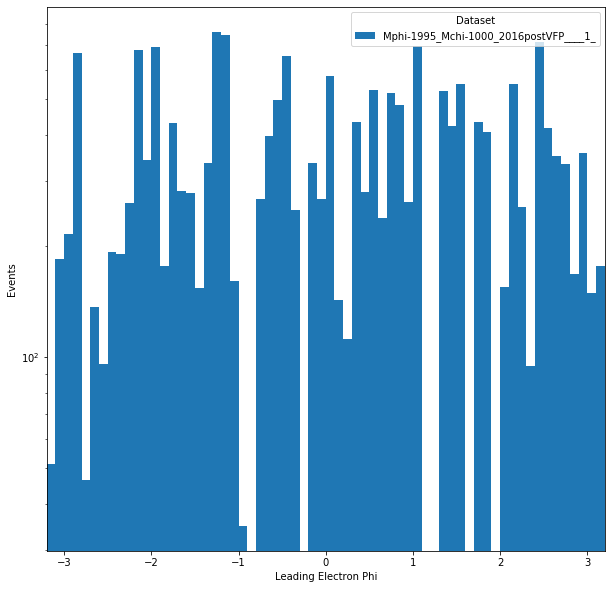

In [4]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))
plot.plot1d(output['ele_phi'].integrate('region', 'wjete').integrate('systematic', 'nominal'), overlay='dataset', ax=ax,
           stack=True)
ax.set_yscale('log')
ax.set_ylim(.1, None)
ax.autoscale()

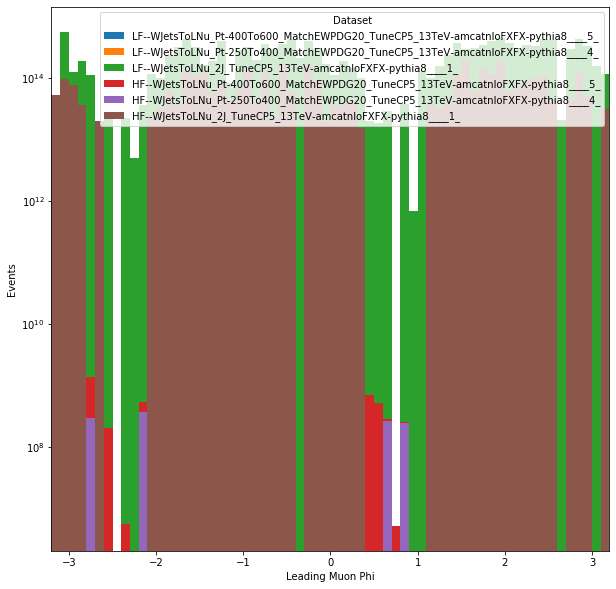

In [6]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))
plot.plot1d(output['mu_phi'].integrate('region').integrate('systematic',), overlay='dataset', ax=ax,
           stack=True)
ax.set_yscale('log')
ax.set_ylim(.1, None)
ax.autoscale()

In [47]:
output['template'].integrate('region', 'ttbare')

<Hist (dataset,systematic,mT) instance at 0x7f1ecd86ac18>

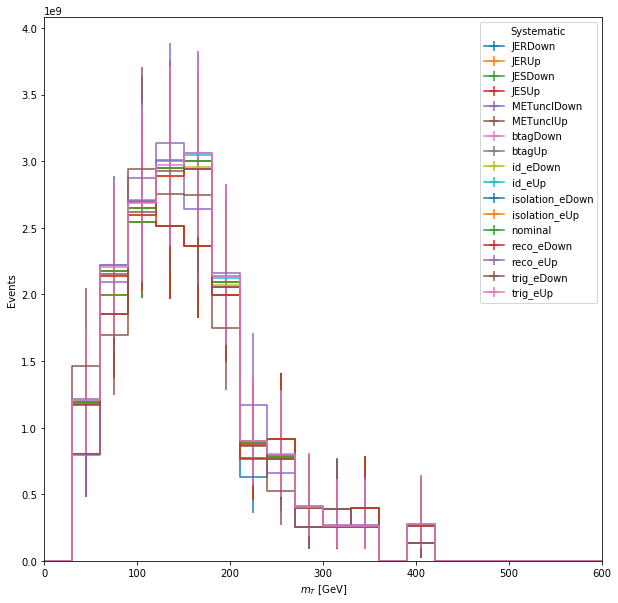

In [68]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))
plot.plot1d(output['template'].integrate('region', 'wjete').integrate('dataset','TTTo2L2Nu_TuneCP5_13TeV-powheg-pythia8preVFP____2_'), overlay='systematic', ax=ax)
# ax.set_yscale('log')
ax.set_ylim(.1, None)
ax.autoscale()

In [26]:
output['template'].integrate('region').integrate('systematic', 'JESUp').values()

{('TTTo2L2Nu_TuneCP5_13TeV-powheg-pythia8preVFP____2_',): array([            nan,  9.10336944e+09,             nan,             nan,
         5.28657953e+10,  4.43299980e+10,  2.93220564e+10,  1.88191384e+10,
         1.06641177e+10,  5.47871686e+09,  3.58538807e+09,  2.23966009e+09,
         1.55435204e+09,  1.08595514e+09, -6.59147407e+06,  0.00000000e+00,
         2.37702722e+08,  1.39076204e+08,  0.00000000e+00,  0.00000000e+00])}

In [7]:
# Define files to run over
#2016preVFP
fileset = {
    'Mphi-1995_Mchi-1000_2016preVFP____0_':
[
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_1.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_2.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_3.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_4.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_5.root"
        ]

}

with open('Signal_2016preVFP_UL.json') as fin:
    samplefiles = json.load(fin)
    xsec = {k: v['xs'] for k,v in samplefiles.items()}

corrections = util.load('../../data/corrections.coffea')
ids         = util.load('../../data/ids.coffea')
common      = util.load('../../data/common.coffea')

# Run Coffea code using uproot
output = processor.run_uproot_job(
    fileset,
    "Events",
    AnalysisProcessor('2016', xsec=xsec,
                           corrections=corrections,
                           ids=ids,
                           common=common),
    processor.futures_executor,
    executor_args={'schema': NanoAODSchema,'workers': 8},
#     chunksize=10000
)

#Run Coffea code using uproot
# output = processor.run_uproot_job(
#     fileset,
#     "Events",
#     AnalysisProcessor('2018', xsec=xsec,
#                            corrections=corrections,
#                            ids=ids,
#                            common=common),
#     processor.iterative_executor,
#     executor_args={'schema': NanoAODSchema,'workers': 4},
# #     skipbadfiles=True
# #     chunksize=10000,
# #     maxchunks=1,
# )

hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC

Scaling: Mphi-1995_Mchi-1000_2016preVFP____0_
Cross section: 1.0


In [2]:
# Define files to run over
#2017
fileset = {
    'Mphi-1995_Mchi-1000_2017____0_':
[
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_1.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_2.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_3.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_4.root",
            "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2017/Mphi-1995_Mchi-1000_2017/Mphi-1995_Mchi-1000_2017_5.root"
        ]

}

with open('Signal_2017_UL.json') as fin:
    samplefiles = json.load(fin)
    xsec = {k: v['xs'] for k,v in samplefiles.items()}

corrections = util.load('../../data/corrections.coffea')
ids         = util.load('../../data/ids.coffea')
common      = util.load('../../data/common.coffea')

# Run Coffea code using uproot
output = processor.run_uproot_job(
    fileset,
    "Events",
    AnalysisProcessor('2017', xsec=xsec,
                           corrections=corrections,
                           ids=ids,
                           common=common),
    processor.futures_executor,
    executor_args={'schema': NanoAODSchema,'workers': 8},
#     chunksize=10000
)

#Run Coffea code using uproot
# output = processor.run_uproot_job(
#     fileset,
#     "Events",
#     AnalysisProcessor('2018', xsec=xsec,
#                            corrections=corrections,
#                            ids=ids,
#                            common=common),
#     processor.iterative_executor,
#     executor_args={'schema': NanoAODSchema,'workers': 4},
# #     skipbadfiles=True
# #     chunksize=10000,
# #     maxchunks=1,
# )

hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC


/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: divide by zero encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: divide by zero encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs


hi I am MC
hi I am MC
hi I am MC
hi I am MC


/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: divide by zero encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs


hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC


/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: divide by zero encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs


hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC


/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: divide by zero encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs


hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC
hi I am MC

Scaling: Mphi-1995_Mchi-1000_2017____0_
Cross section: 1.0


In [5]:
import numpy as np

In [3]:
dataset = "Mphi-1995_Mchi-1000_2017____0_"


In [4]:
save(output,'../../hists/UL_lep_monotop_v1_test_2017'+'/'+dataset+'.futures')

In [11]:
# Define files to run over
#2018
fileset = {
#     'Mphi-1995_Mchi-1000_2018____0_':
#     [
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-1995_Mchi-1000_2018/Mphi-1995_Mchi-1000_2018_1.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-1995_Mchi-1000_2018/Mphi-1995_Mchi-1000_2018_2.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-1995_Mchi-1000_2018/Mphi-1995_Mchi-1000_2018_3.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-1995_Mchi-1000_2018/Mphi-1995_Mchi-1000_2018_4.root",
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-1995_Mchi-1000_2018/Mphi-1995_Mchi-1000_2018_5.root"
#         ]
    "WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____4_": 
    [
"root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/8A16FAF9-40C4-9042-A888-CC6FF79132BD.root",
#                     "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/7FFCDC32-7714-6E4F-B67D-D5249140BD2F.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/D62C3915-5A89-0245-B798-CA424003CE1E.root",
        ],

#     'DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8____10_':
#     [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/280000/97462A82-F521-A24F-A8C0-56F01BD30C72.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/280000/D3ACDDBA-188E-F243-BD2D-966FFCBA219E.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/280000/27CBA0D1-3CE7-1A44-A935-DD513E0D01EE.root"
#         ],
#     'EGamma____1_':
#     [
        
#             "root://cmsxrootd.fnal.gov//store/data/Run2018A/EGamma/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v1/270000/F8F84CA2-7E90-2D45-98B0-2773BCDCEF1D.root",
#             "root://cmsxrootd.fnal.gov//store/data/Run2018A/EGamma/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v1/270000/EB703433-936F-F942-9341-635CB46ADD71.root",
#             "root://cmsxrootd.fnal.gov//store/data/Run2018A/EGamma/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v1/270000/95A159AA-5B87-DA42-B1C9-DCC030E5A0FE.root"
        
#     ],
#     'QCD_Pt_30to50_TuneCP5_13TeV_pythia8____1_':
#     [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/QCD_Pt_30to50_TuneCP5_13TeV_pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/38083213-C442-0C4A-A764-C664F23C4B6B.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/QCD_Pt_30to50_TuneCP5_13TeV_pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/70000/E01217C3-4EBD-0C4B-92B4-CA4439D320B9.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/QCD_Pt_30to50_TuneCP5_13TeV_pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/280000/C08321A4-F291-AA48-88B5-3B2379EB4CF3.root"
#         ]
}

with open('../../metadata/UL_2018.json') as fin:
    samplefiles = json.load(fin)
    xsec = {k: v['xs'] for k,v in samplefiles.items()}

corrections = util.load('../../data/corrections.coffea')
ids         = util.load('../../data/ids.coffea')
common      = util.load('../../data/common.coffea')

# Run Coffea code using uproot
output = processor.run_uproot_job(
    fileset,
    "Events",
    AnalysisProcessor('2018', xsec=xsec,
                           corrections=corrections,
                           ids=ids,
                           common=common),
    processor.futures_executor,
    executor_args={'schema': NanoAODSchema,'workers': 1},
#     chunksize=10000
)

#Run Coffea code using uproot
# output = processor.run_uproot_job(
#     fileset,
#     "Events",
#     AnalysisProcessor('2018', xsec=xsec,
#                            corrections=corrections,
#                            ids=ids,
#                            common=common),
#     processor.iterative_executor,
#     executor_args={'schema': NanoAODSchema,'workers': 4},
# #     skipbadfiles=True
# #     chunksize=10000,
# #     maxchunks=1,
# )

hi I am MC


/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: divide by zero encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs


atleast_one_jet_with_pt_grt_50 [ True  True  True ...  True  True  True] 
SUM: 116754
events left 116754.0
met100 [False  True  True ...  True False False] 
SUM: 56869
events left 50020.0
Delta_Phi_Met_LJ [ True  True  True ...  True  True  True] 
SUM: 108576
events left 48928.0
zero_medium_btags [ True  True  True ...  True  True  True] 
SUM: 124980
events left 46027.0
isoneE [False False False ... False False  True] 
SUM: 19936
events left 2773.0
met_filters [ True  True  True ...  True  True  True] 
SUM: 132915
events left 2773.0
single_electron_triggers [False False False ... False False  True] 
SUM: 24035
events left 2535.0
mt_wjete>50 [False False False ... False False False] 
SUM: 12030
events left 1538.0
noHEMj [ True  True  True ...  True  True  True] 
SUM: 117065
events left 1334.0
noHEMmet [ True  True  True ...  True  True  True] 
SUM: 112950
events left 1127.0
exclude_dyjets_less_400 [ True  True  True ...  True  True  True] 
SUM: 133026
events left 1127.0
exclude_dyjets_g

SystemExit: 0

In [8]:
dataset = "Mphi-1995_Mchi-1000_2018____0_"


In [12]:
!pwd

/cms/scratch/runiyal/new_coffea/decaf/analysis/Rishabh_NB/new_coffea_nbs


In [9]:
save(output,'../../hists/UL_lep_monotop_v1_test_2018'+'/'+dataset+'.futures')

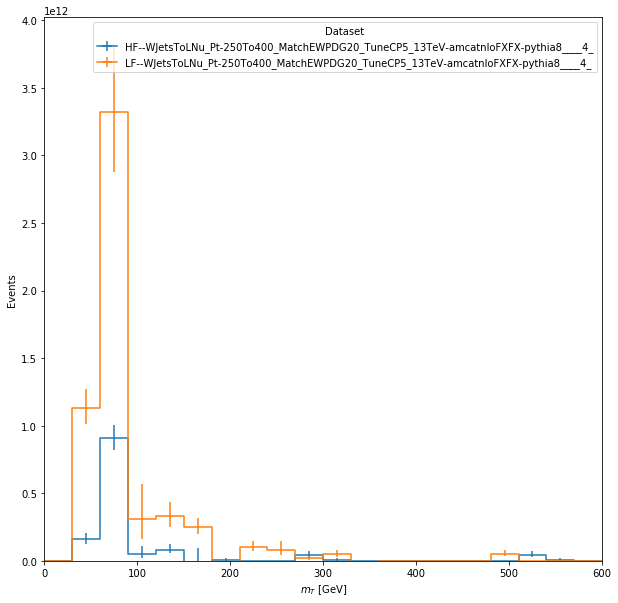

In [31]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))

plot.plot1d(output['mT'].integrate('region', 'wjete'),            
        overlay="dataset",
        ax=ax,
        clear=False,
#             stack=True
           )


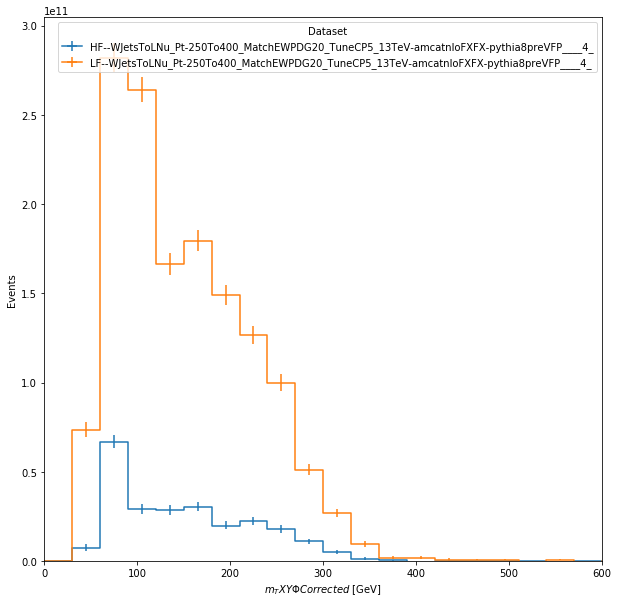

In [10]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))

plot.plot1d(output['mT_corrected'].integrate('region', 'wjete'),            
        overlay="dataset",
        ax=ax,
        clear=False,
#             stack=True
           )


In [12]:
output['mT_corrected'].integrate('region', 'wjete')

<Hist (dataset,mT_corrected) instance at 0x7fd531ce7cf8>

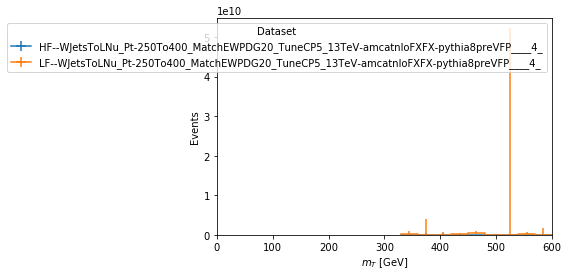

In [16]:
plot.plot1d(output['template'].integrate('region').integrate('systematic', 'JESUp'), overlay='dataset')

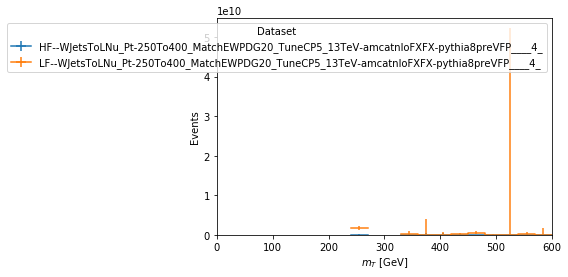

In [18]:
plot.plot1d(output['template'].integrate('region').integrate('systematic', 'JESDown'), overlay='dataset')